<a href="https://www.kaggle.com/code/lalit7881/global-product-prices-eda?scriptVersionId=359345871" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/vedauv/global-retail-and-e-commerce-product-price/global_retail_prices_dataset.csv
/kaggle/input/datasets/vedauv/global-retail-and-e-commerce-product-price/datasheet.md
/kaggle/input/datasets/vedauv/global-retail-and-e-commerce-product-price/README.md


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/vedauv/global-retail-and-e-commerce-product-price/global_retail_prices_dataset.csv")

In [3]:
df.head()

,price_record_id,product_code,product_name,brand,category,price,currency,price_is_discounted,store_name,city,country_code,date_recorded
0,339639,NaN,APFEL ROT LOSE,NaN,en:apples,2.08,EUR,False,jbieber,Hofer,NaN,2026-10-03
1,339638,4061461467661,Orient. Salat 200g,NaN,NaN,1.29,EUR,False,jbieber,Hofer,NaN,2026-10-03
2,339637,NaN,Toskanabrot 360g,NaN,en:white-breads,1.80,EUR,False,jbieber,Hofer,NaN,2026-10-03
3,339636,4061464512245,Waffelhörn. Erdb.,NaN,NaN,0.49,EUR,False,jbieber,Hofer,NaN,2026-10-03
4,339635,4061458026819,Orient. Salat 200g,NaN,NaN,1.29,EUR,False,jbieber,Hofer,NaN,2026-10-03


In [4]:
df.head()

,price_record_id,product_code,product_name,brand,category,price,currency,price_is_discounted,store_name,city,country_code,date_recorded
0,339639,NaN,APFEL ROT LOSE,NaN,en:apples,2.08,EUR,False,jbieber,Hofer,NaN,2026-10-03
1,339638,4061461467661,Orient. Salat 200g,NaN,NaN,1.29,EUR,False,jbieber,Hofer,NaN,2026-10-03
2,339637,NaN,Toskanabrot 360g,NaN,en:white-breads,1.80,EUR,False,jbieber,Hofer,NaN,2026-10-03
3,339636,4061464512245,Waffelhörn. Erdb.,NaN,NaN,0.49,EUR,False,jbieber,Hofer,NaN,2026-10-03
4,339635,4061458026819,Orient. Salat 200g,NaN,NaN,1.29,EUR,False,jbieber,Hofer,NaN,2026-10-03


In [5]:
df.tail()

,price_record_id,product_code,product_name,brand,category,price,currency,price_is_discounted,store_name,city,country_code,date_recorded
1995,337613,3497917000907,BRETS CHIPS FROMAGE JURA 0.125 kg,NaN,NaN,1.12,EUR,False,poslovitch,Intermarché,NaN,2026-09-30
1996,337612,3250393446214,PAQUITO BIO PJ CAROTTE 1L,NaN,NaN,2.96,EUR,False,poslovitch,Intermarché,NaN,2026-09-30
1997,337611,3250393446177,PAQUITO BIO PJ MULTIFRT 1 PAQUITO,NaN,NaN,2.88,EUR,False,poslovitch,Intermarché,NaN,2026-09-30
1998,337610,3123349017670,JOKER JUS MATIN+ MANDA 90,NaN,NaN,2.44,EUR,False,poslovitch,Intermarché,NaN,2026-09-30
1999,337609,3250390003656,JUS DE TOMATE PET PAQUITO,NaN,NaN,2.12,EUR,False,poslovitch,Intermarché,NaN,2026-09-30


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   price_record_id      2000 non-null   int64  
 1   product_code         1866 non-null   object 
 2   product_name         1539 non-null   object 
 3   brand                0 non-null      float64
 4   category             134 non-null    object 
 5   price                2000 non-null   float64
 6   currency             2000 non-null   object 
 7   price_is_discounted  2000 non-null   bool   
 8   store_name           2000 non-null   object 
 9   city                 2000 non-null   object 
 10  country_code         0 non-null      float64
 11  date_recorded        2000 non-null   object 
dtypes: bool(1), float64(3), int64(1), object(7)
memory usage: 174.0+ KB


In [7]:
df.describe()

,price_record_id,brand,price,country_code
count,2000.000000,0.0,2000.000000,0.0
mean,338628.300500,NaN,34.239621,NaN
std,587.603024,NaN,206.362881,NaN
min,337609.000000,NaN,0.230000,NaN
25%,338121.750000,NaN,2.280000,NaN
50%,338631.500000,NaN,4.370000,NaN
75%,339139.250000,NaN,15.990000,NaN
max,339639.000000,NaN,5030.000000,NaN


In [8]:
df.isnull().sum()

price_record_id           0
product_code            134
product_name            461
brand                  2000
category               1866
price                     0
currency                  0
price_is_discounted       0
store_name                0
city                      0
country_code           2000
date_recorded             0
dtype: int64

In [9]:
df.dtypes

price_record_id          int64
product_code            object
product_name            object
brand                  float64
category                object
price                  float64
currency                object
price_is_discounted       bool
store_name              object
city                    object
country_code           float64
date_recorded           object
dtype: object

In [10]:
df.shape

(2000, 12)

In [11]:
df.isnull().sum()

price_record_id           0
product_code            134
product_name            461
brand                  2000
category               1866
price                     0
currency                  0
price_is_discounted       0
store_name                0
city                      0
country_code           2000
date_recorded             0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.columns

Index(['price_record_id', 'product_code', 'product_name', 'brand', 'category',
       'price', 'currency', 'price_is_discounted', 'store_name', 'city',
       'country_code', 'date_recorded'],
      dtype='object')

In [14]:
df.nunique()

price_record_id        2000
product_code           1761
product_name           1516
brand                     0
category                 64
price                   608
currency                 20
price_is_discounted       1
store_name               63
city                     79
country_code              0
date_recorded            51
dtype: int64

## EDA

PRODUCT PRICE ANALYSIS AND VISUALIZATION

Original dataset shape: (2000, 12)

Column data types:
price_record_id          int64
product_code            object
product_name            object
brand                  float64
category                object
price                  float64
currency                object
price_is_discounted       bool
store_name              object
city                    object
country_code           float64
date_recorded           object
dtype: object

DATA QUALITY SUMMARY
Duplicate rows removed: 0
Rows after duplicate removal: 2000
Valid positive-price records: 2000
Missing values by column:

price_record_id           0
product_code            134
product_name            461
brand                  2000
category               1866
price                     0
currency                  0
price_is_discounted       0
store_name                0
city                      0
country_code           2000
date_recorded             0
dtype: int64

PRICE STATISTICS
count

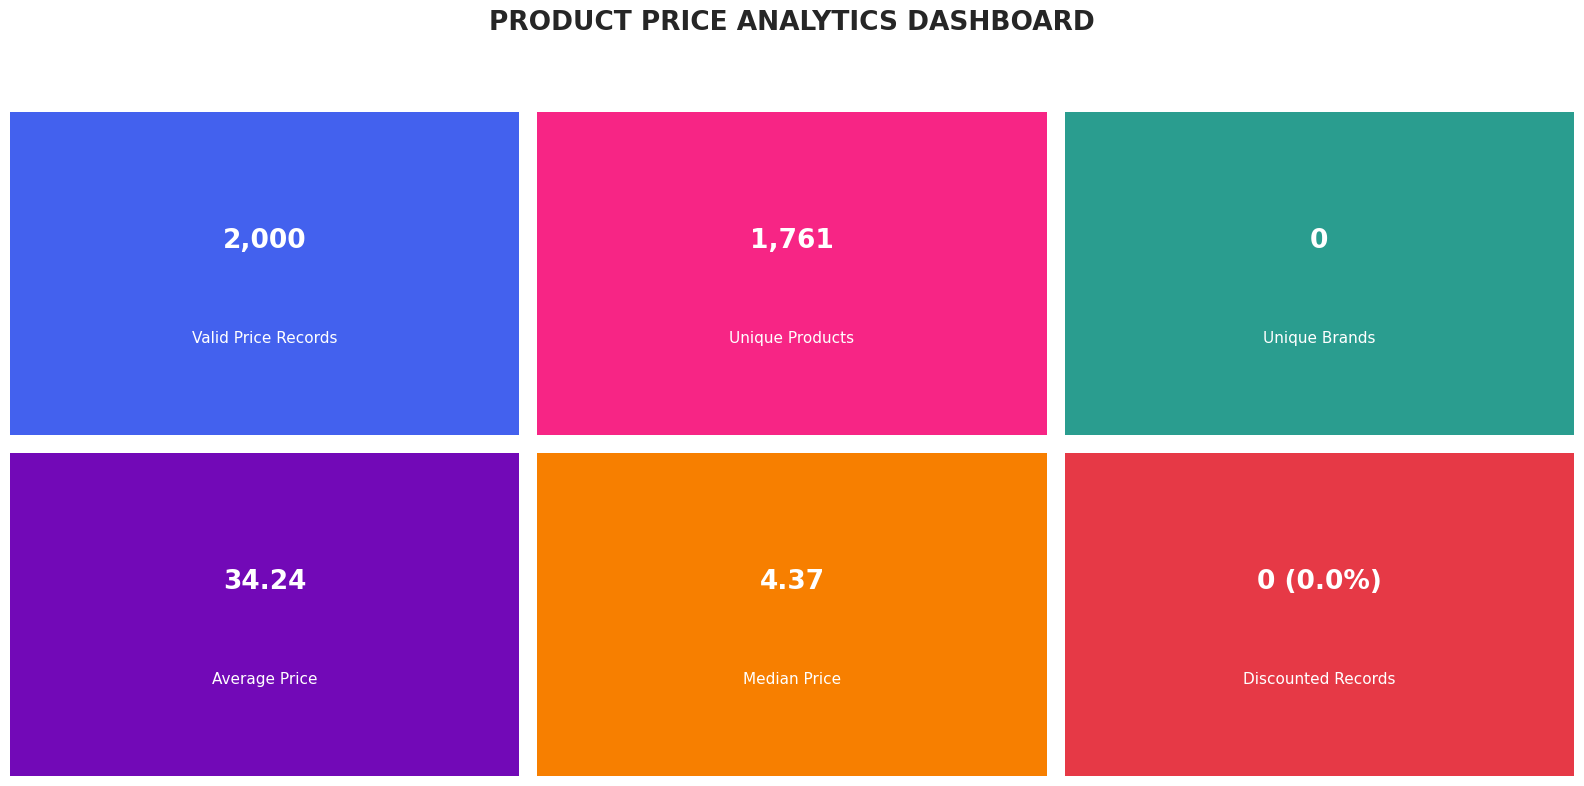

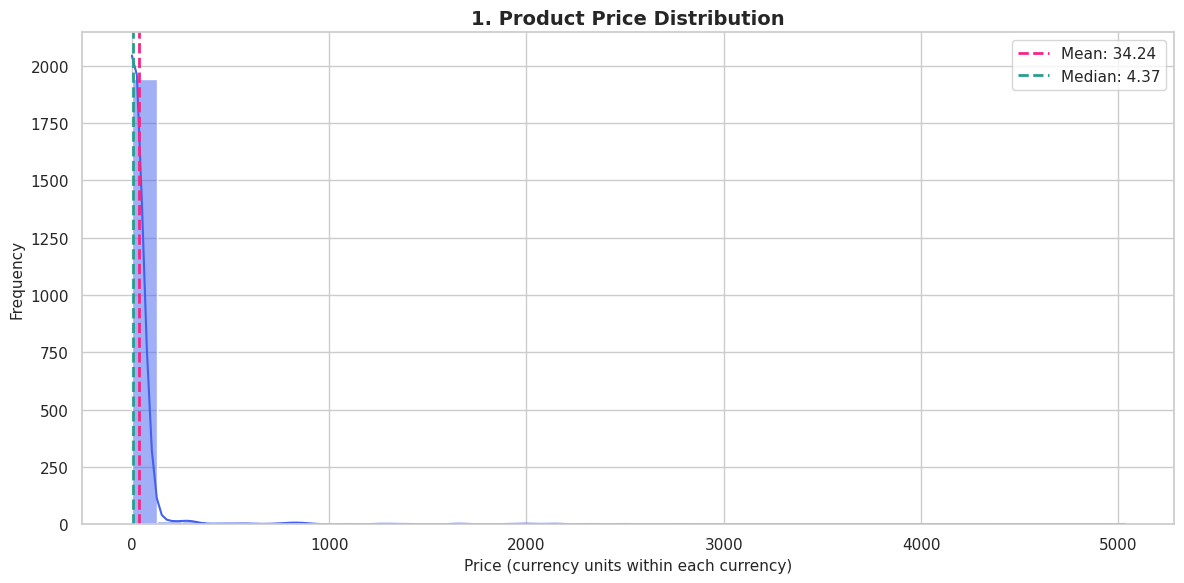

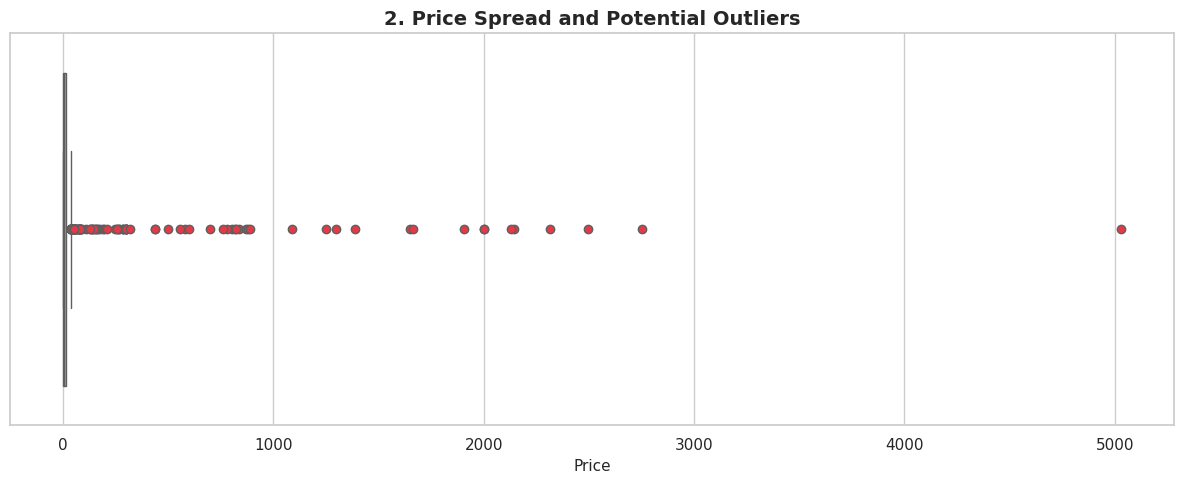

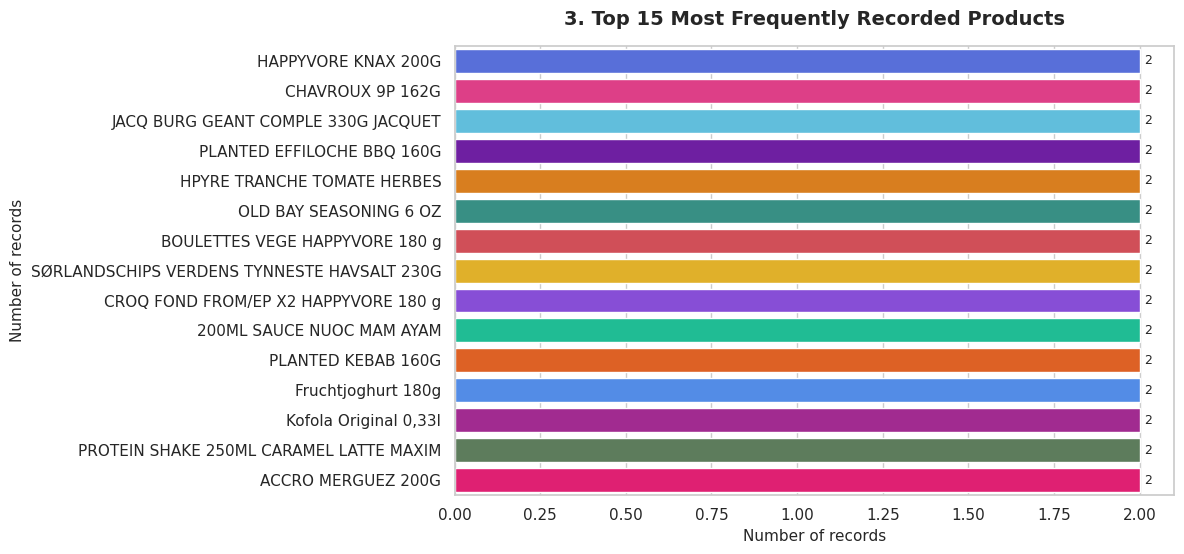

Skipping '4. Top 15 Brands by Number of Price Records': no usable data.


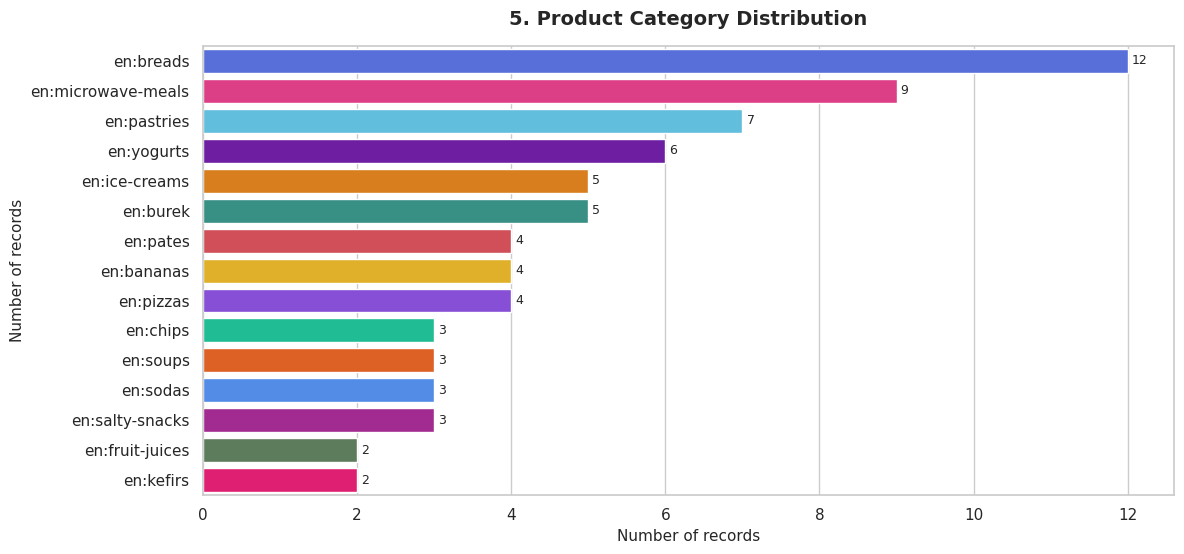

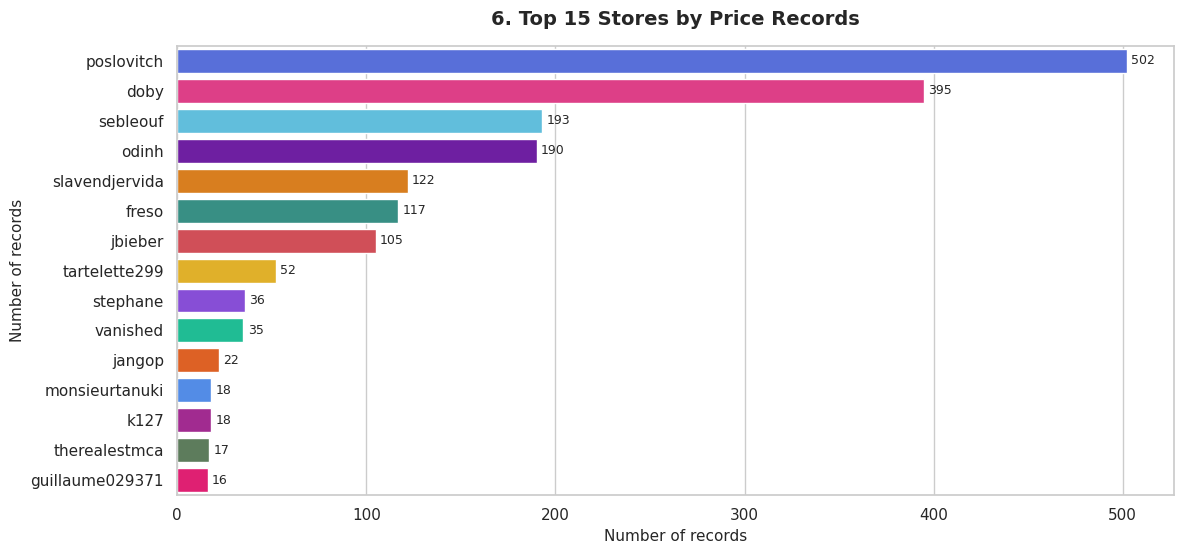

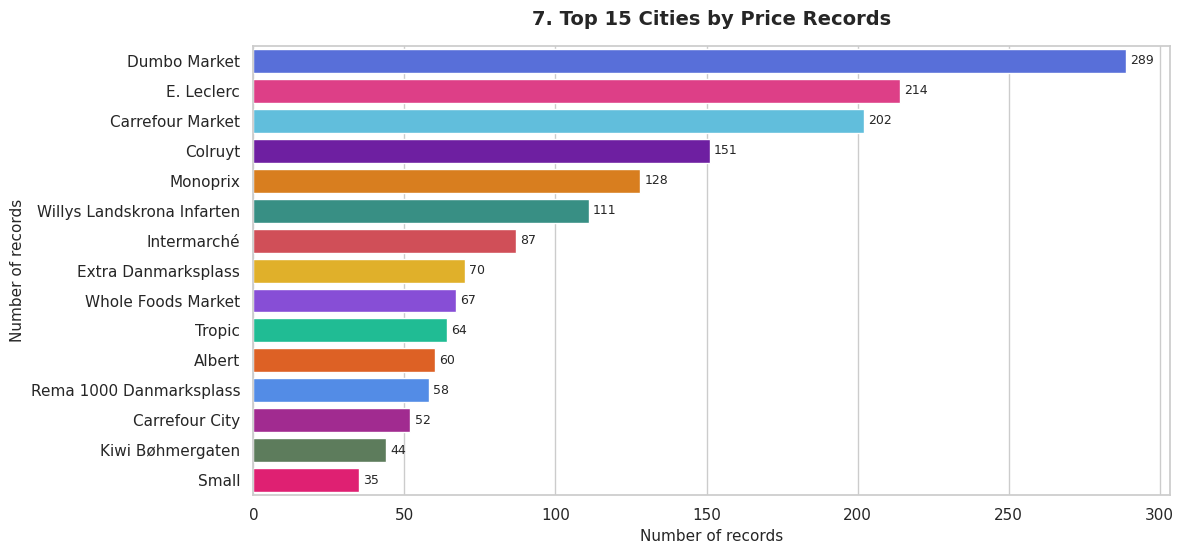

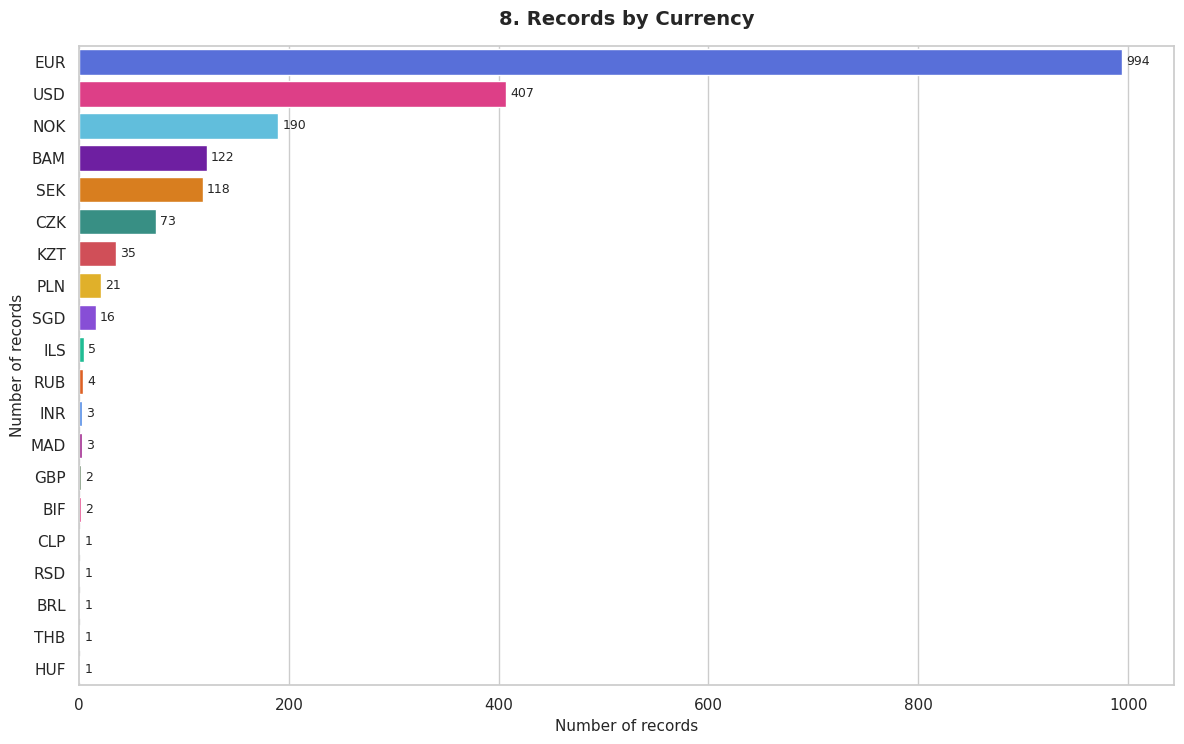

Skipping '9. Country-Wise Product Price Records': no usable data.


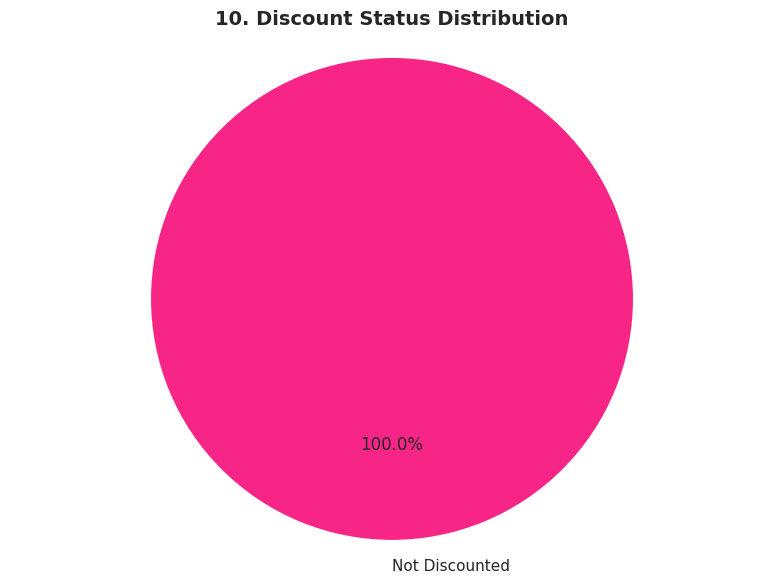

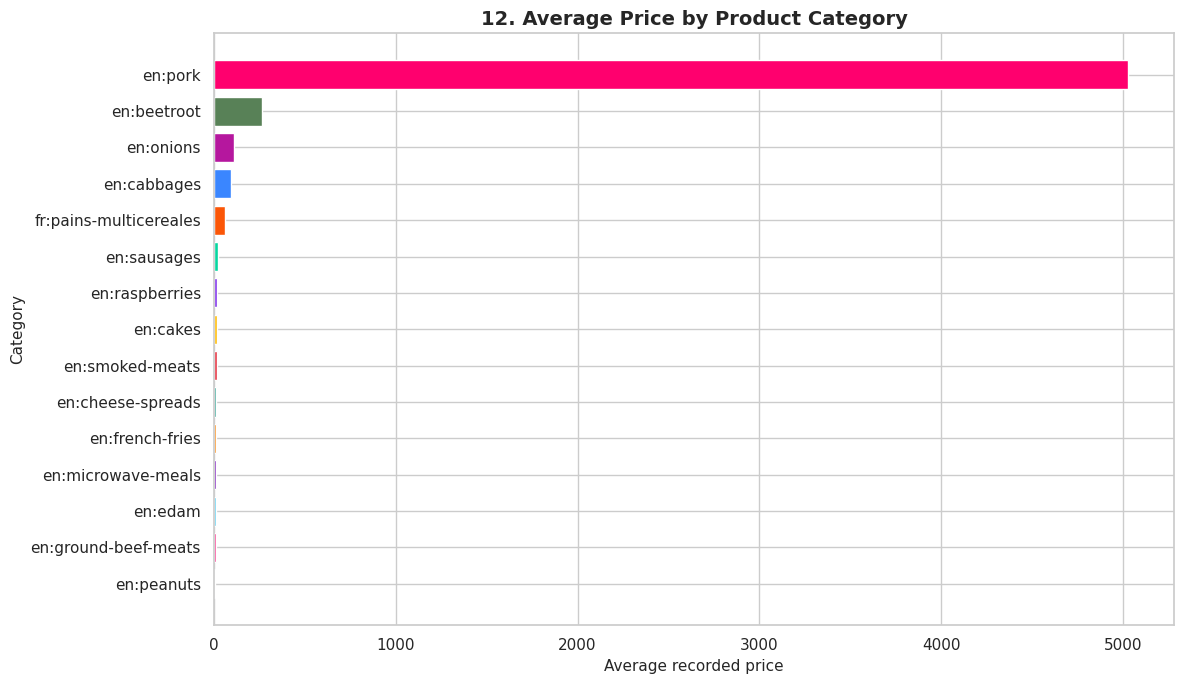

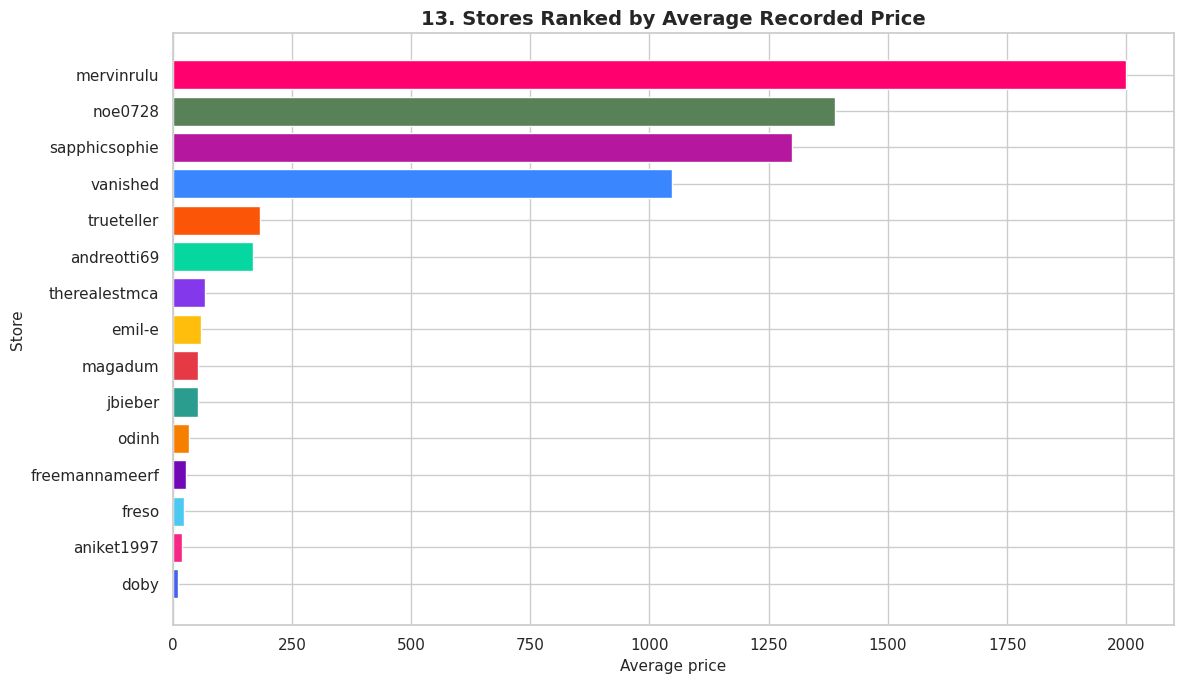

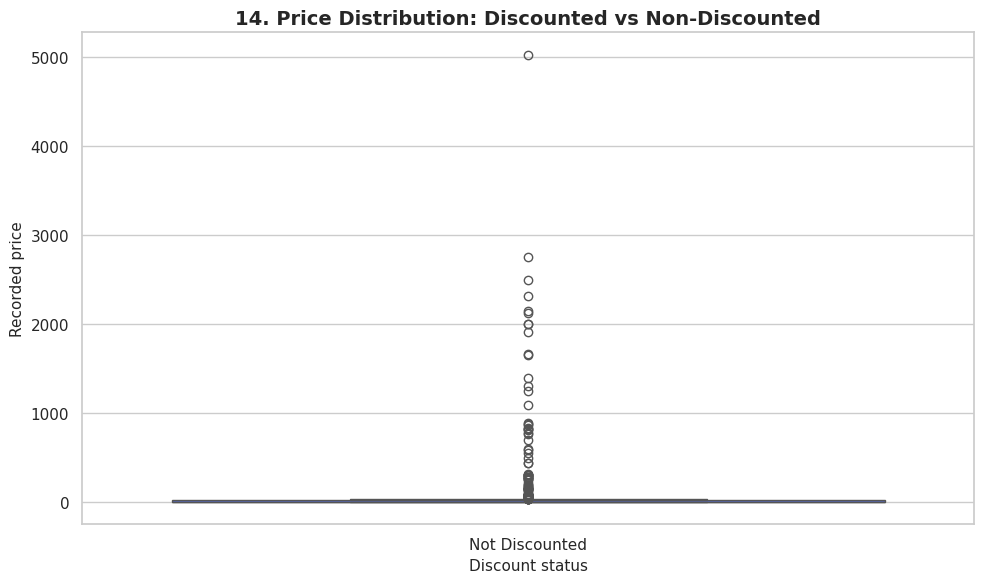


Average and median price by currency:
             mean   median  count
currency                         
EUR          3.20     2.50    994
USD         10.88     9.49    407
NOK         34.93    31.70    190
BAM          4.35     2.47    122
SEK         23.97    22.90    118
CZK         73.13    35.90     73
KZT       1047.31   779.00     35
PLN          9.80     5.79     21
SGD          3.32     2.88     16
ILS          6.34     5.90      5
RUB         53.75    50.00      4
MAD          9.00     2.00      3
INR        129.33   159.00      3
GBP          1.90     1.90      2
BIF       2000.00  2000.00      2
BRL          6.99     6.99      1
CLP       1390.00  1390.00      1
HUF       1299.00  1299.00      1
RSD        169.00   169.00      1
THB       1090.00  1090.00      1


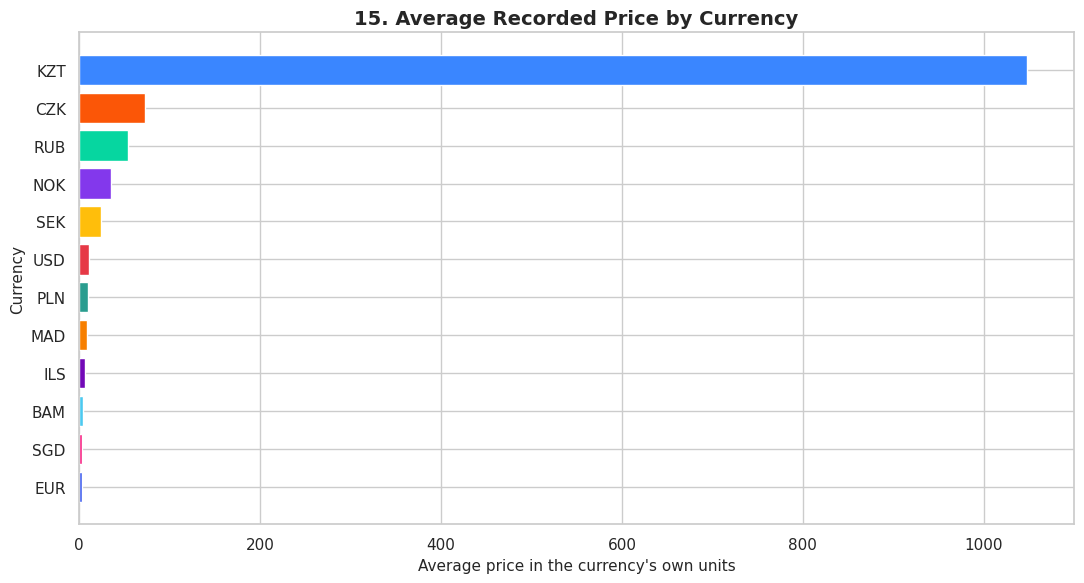

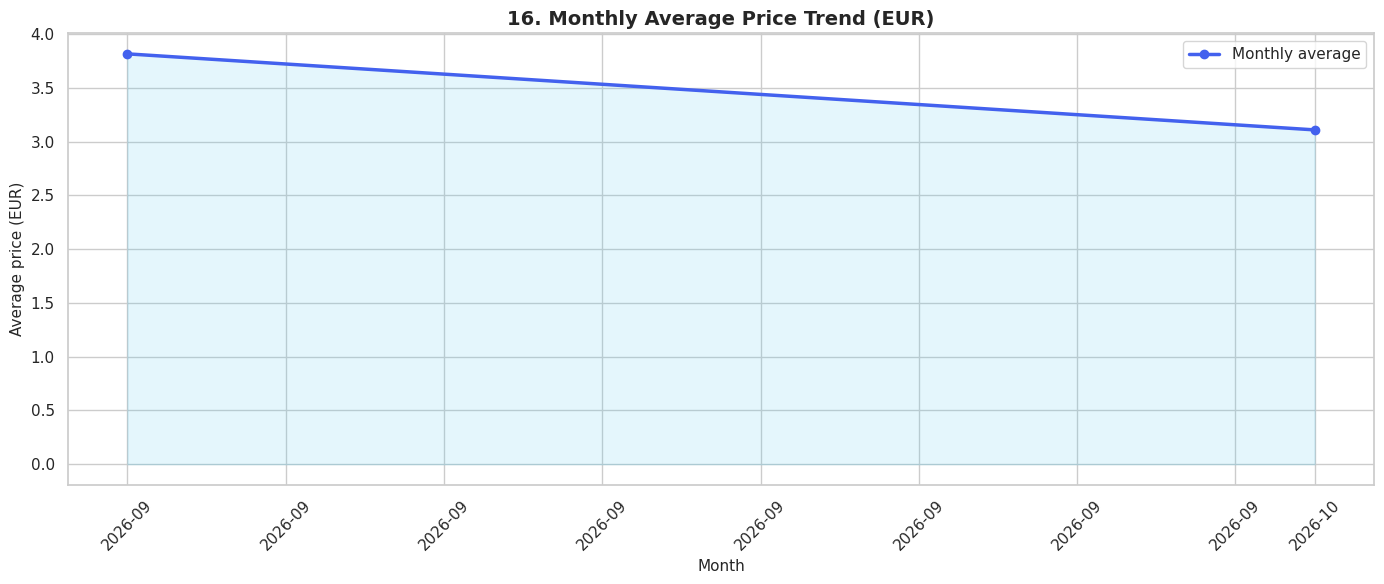

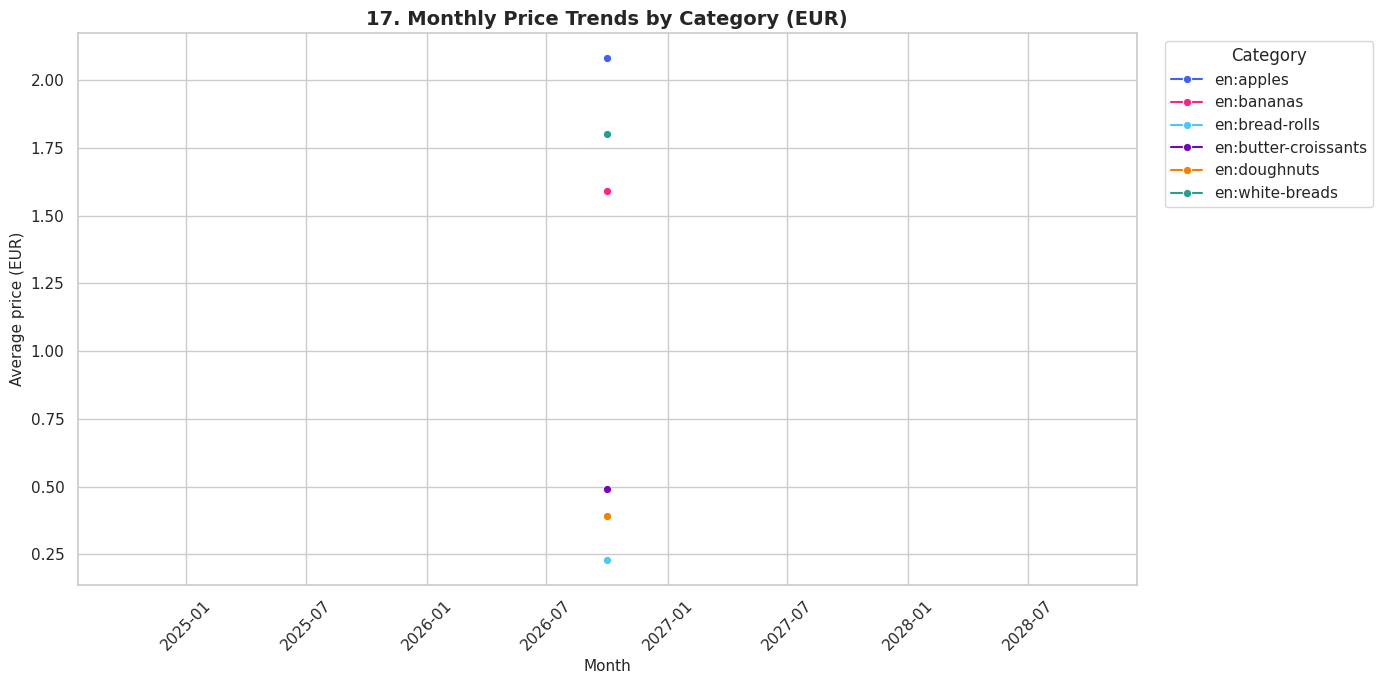

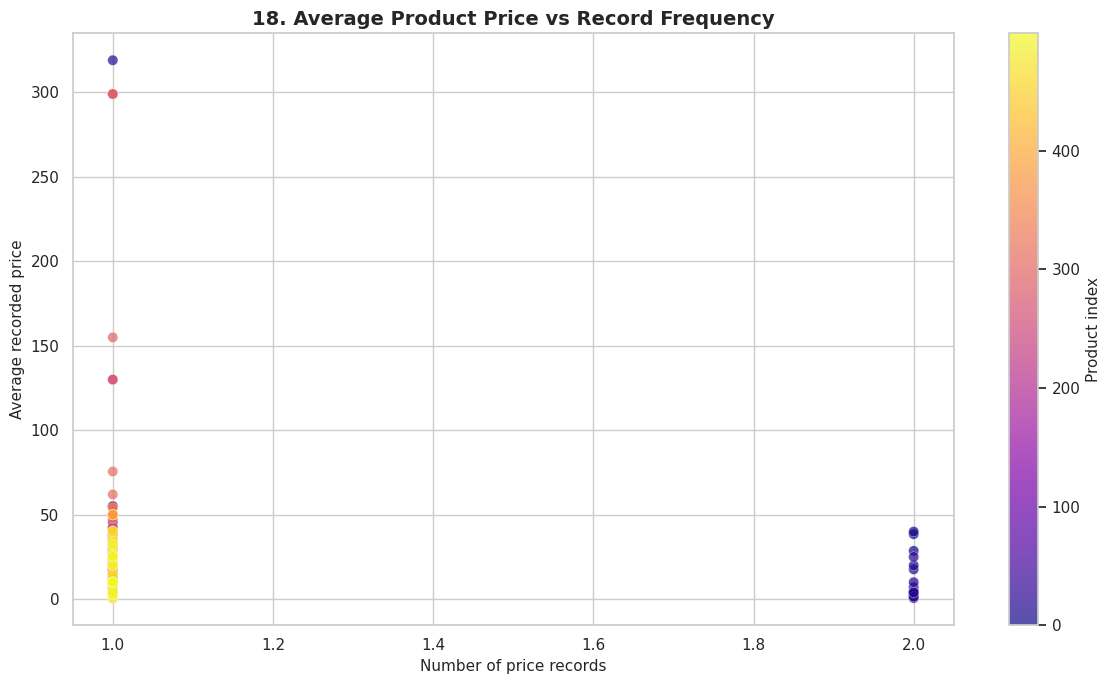

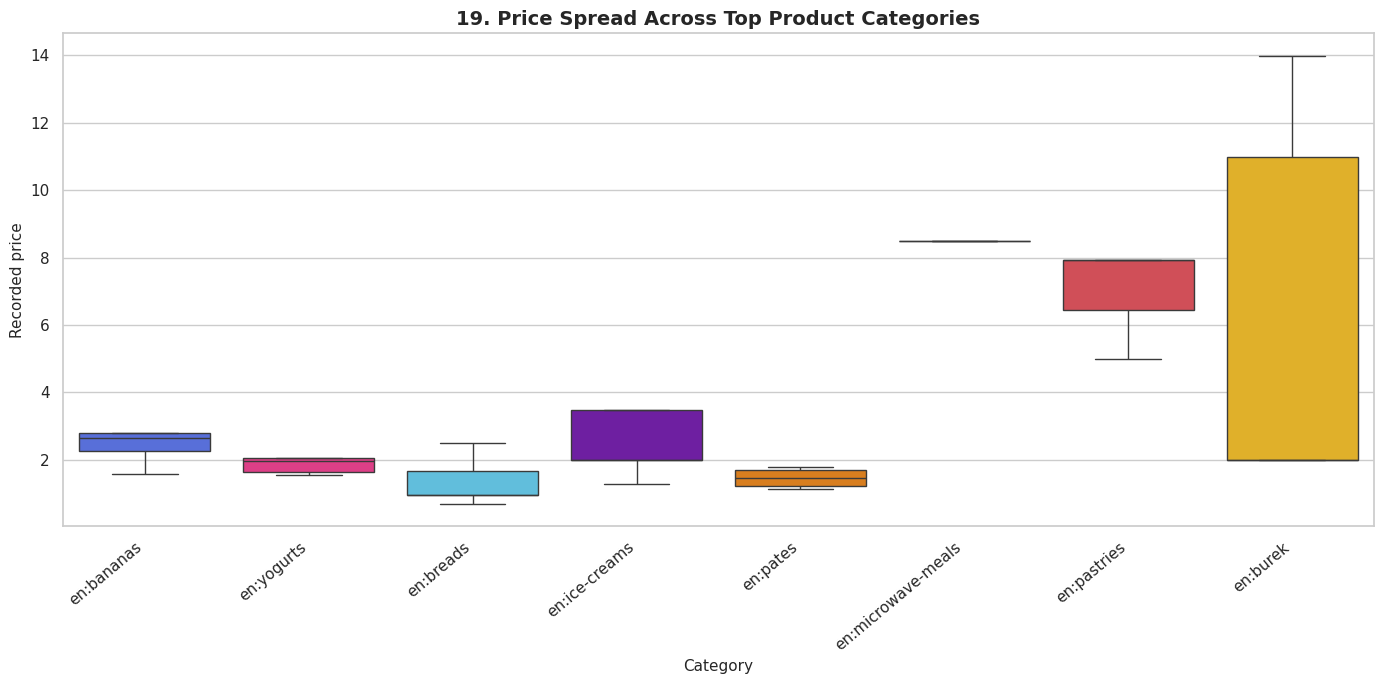

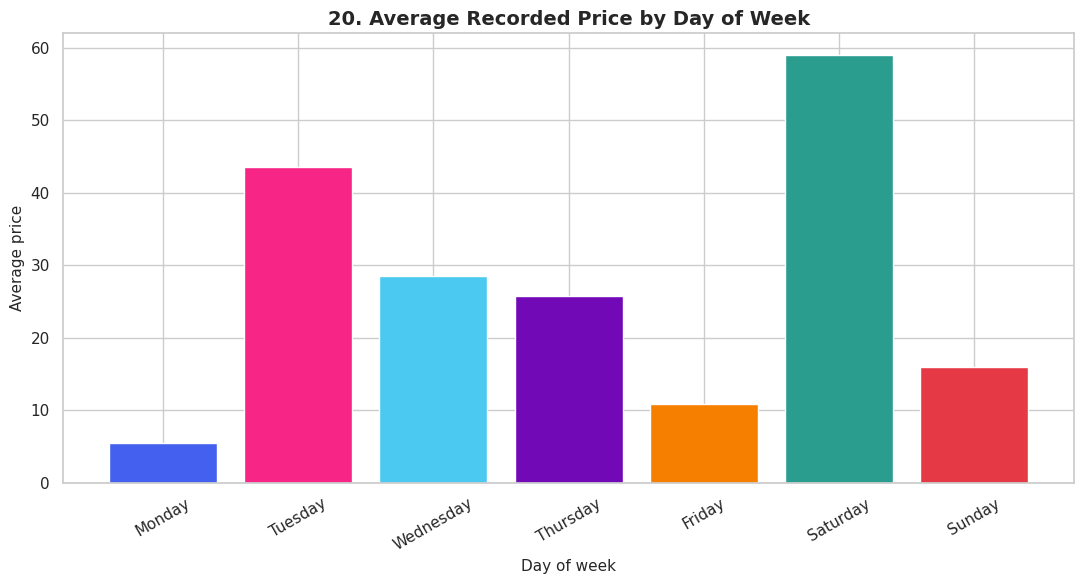


TOP 15 HIGHEST-PRICE RECORDS
                       product_name brand category  price currency    store_name
              Картофель мытый пакет  <NA>  en:pork 5030.0      KZT      vanished
          Коньяк Арарат 5* 40% 0.7л  <NA>     <NA> 2755.0      KZT      vanished
              Ликер Малибу 21% 0.5л  <NA>     <NA> 2495.0      KZT      vanished
          Виски Джек Дэниэлс 40% 1л  <NA>     <NA> 2315.0      KZT      vanished
      Коньяк Торрес 10 лет 38% 0.7л  <NA>     <NA> 2145.0      KZT      vanished
         Кетчуп Хайнц томатный 550г  <NA>     <NA> 2128.0      KZT      vanished
                               <NA>  <NA>     <NA> 2000.0      BIF    mervinrulu
                               <NA>  <NA>     <NA> 2000.0      BIF    mervinrulu
                               <NA>  <NA>     <NA> 1909.0      KZT      vanished
                               <NA>  <NA>     <NA> 1665.0      KZT      vanished
                               <NA>  <NA>     <NA> 1650.0      KZT      vanishe

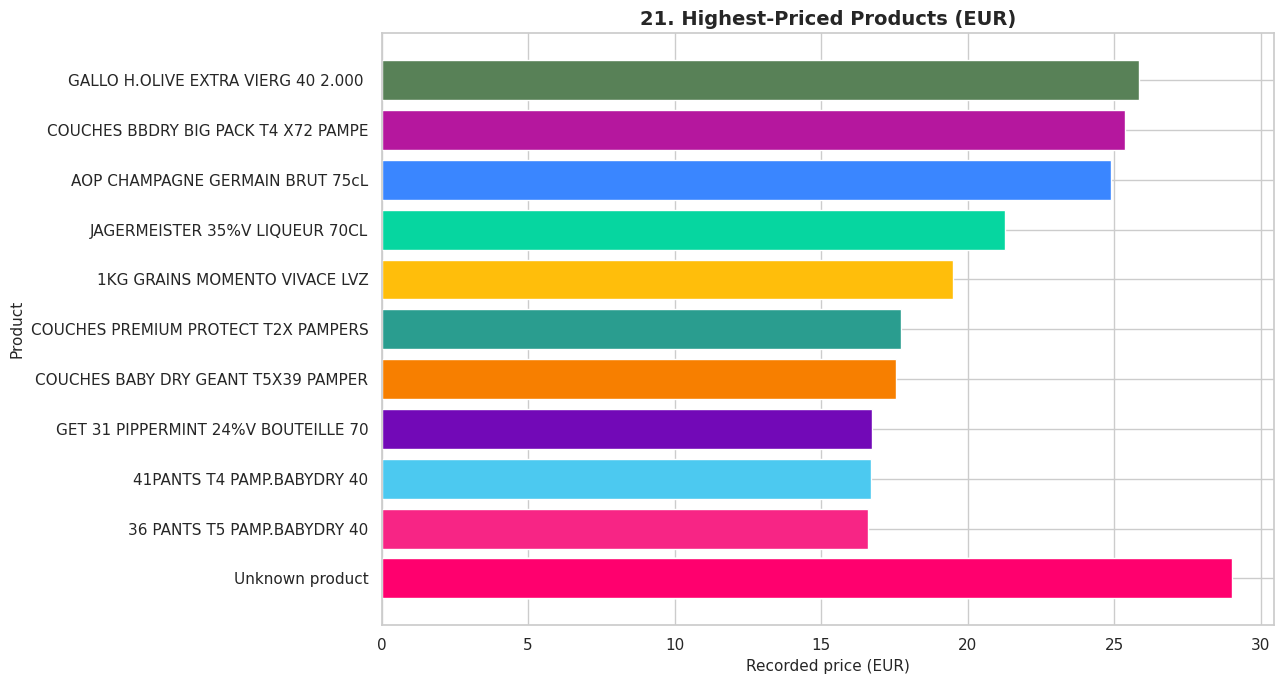

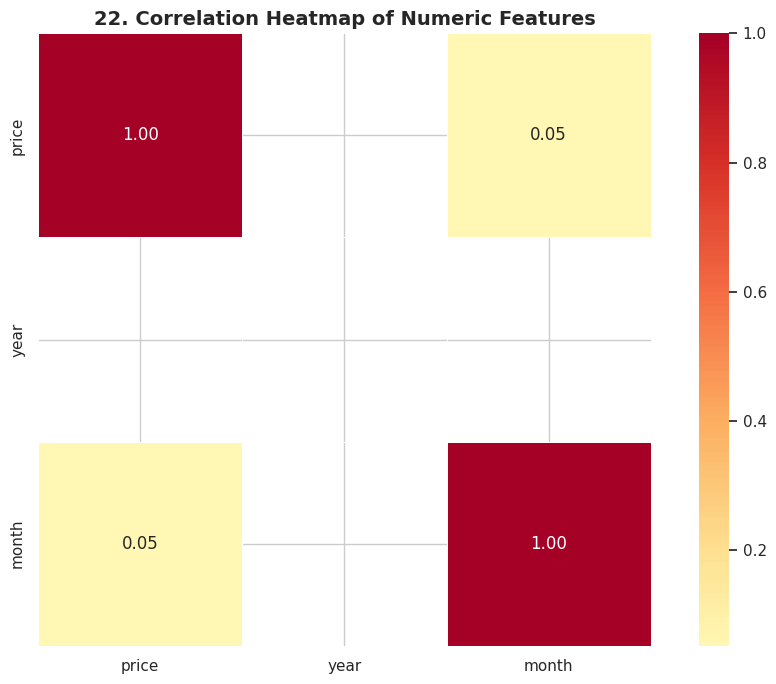

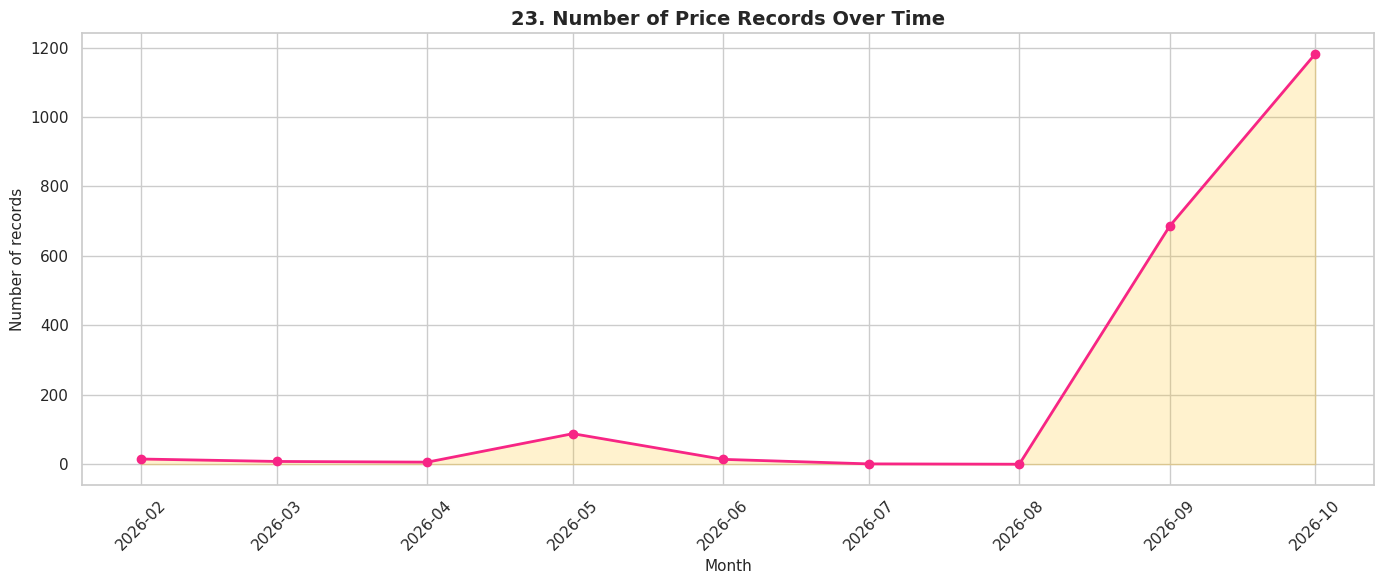


TOP BRANDS SUMMARY
Empty DataFrame
Columns: [records, average_price, median_price, minimum_price, maximum_price]
Index: []

TOP CATEGORIES SUMMARY
                         records  average_price  median_price  unique_products
category                                                                      
en:breads                     12           1.37          0.95                0
en:microwave-meals             9           9.43          8.49                0
en:pastries                    7           6.87          7.93                0
en:yogurts                     6           2.03          1.97                0
en:ice-creams                  5           3.99          1.99                0
en:burek                       5           6.19          1.99                0
en:bananas                     4           2.42          2.64                0
en:pizzas                      4           4.99          2.99                0
en:pates                       4           1.47          1.47 

In [15]:

# ================================================================
# PRODUCT PRICE ANALYSIS & VISUALIZATION - COMPLETE SINGLE CELL
# ================================================================
# Dataset columns:
# price_record_id, product_code, product_name, brand, category,
# price, currency, price_is_discounted, store_name, city,
# country_code, date_recorded
#
# Libraries: Pandas, NumPy, Matplotlib, Seaborn
# Charts: 20+ detailed visualizations with different colors
# ================================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# -------------------- CONFIGURATION --------------------

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 100

# Different colors for charts
PALETTE = [
    "#4361EE", "#F72585", "#4CC9F0", "#7209B7",
    "#F77F00", "#2A9D8F", "#E63946", "#FFBE0B",
    "#8338EC", "#06D6A0", "#FB5607", "#3A86FF",
    "#B5179E", "#588157", "#FF006E", "#8ECAE6"
]

# -------------------- VALIDATE DATA --------------------

if "df" not in globals():
    raise NameError(
        "DataFrame 'df' not found. Load your dataset into df first."
    )

required_columns = [
    "price_record_id", "product_code", "product_name", "brand",
    "category", "price", "currency", "price_is_discounted",
    "store_name", "city", "country_code", "date_recorded"
]

missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Work on a copy to preserve the original DataFrame
data = df[required_columns].copy()

print("=" * 75)
print("PRODUCT PRICE ANALYSIS AND VISUALIZATION")
print("=" * 75)

print("\nOriginal dataset shape:", data.shape)
print("\nColumn data types:")
print(data.dtypes)

# -------------------- DATA CLEANING --------------------

# Remove duplicate rows
duplicate_count = data.duplicated().sum()
data = data.drop_duplicates().copy()

# Convert price into numeric values
data["price"] = pd.to_numeric(data["price"], errors="coerce")

# Convert date
data["date_recorded"] = pd.to_datetime(
    data["date_recorded"], errors="coerce"
)

# Clean categorical text columns
categorical_columns = [
    "product_code", "product_name", "brand", "category",
    "currency", "store_name", "city", "country_code"
]

for col in categorical_columns:
    data[col] = data[col].astype("string").str.strip()
    data[col] = data[col].replace("", pd.NA)

# Normalize discount indicators
def normalize_discount(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    value = str(value).strip().lower()
    if value in ["true", "1", "yes", "y", "discounted"]:
        return True
    if value in ["false", "0", "no", "n", "not discounted"]:
        return False
    return np.nan

data["price_is_discounted"] = data[
    "price_is_discounted"
].apply(normalize_discount)

# Create a cleaned analytical dataset
# Keep only positive prices for price-based visualizations.
price_data = data[
    data["price"].notna() & (data["price"] > 0)
].copy()

# Derived time columns
price_data["year"] = price_data["date_recorded"].dt.year
price_data["month"] = price_data["date_recorded"].dt.month
price_data["month_name"] = price_data["date_recorded"].dt.strftime("%b")
price_data["year_month"] = (
    price_data["date_recorded"].dt.to_period("M").astype(str)
)
price_data["weekday"] = price_data["date_recorded"].dt.day_name()

# -------------------- SUMMARY --------------------

print("\n" + "=" * 75)
print("DATA QUALITY SUMMARY")
print("=" * 75)

print("Duplicate rows removed:", duplicate_count)
print("Rows after duplicate removal:", len(data))
print("Valid positive-price records:", len(price_data))
print("Missing values by column:\n")
print(data.isnull().sum())

if price_data.empty:
    raise ValueError(
        "No valid positive prices found. Check the price column."
    )

print("\n" + "=" * 75)
print("PRICE STATISTICS")
print("=" * 75)

print(price_data["price"].describe().round(2))

print("\nUnique products:", price_data["product_code"].nunique())
print("Unique brands:", price_data["brand"].nunique())
print("Unique categories:", price_data["category"].nunique())
print("Unique stores:", price_data["store_name"].nunique())
print("Unique cities:", price_data["city"].nunique())
print("Currencies:", price_data["currency"].nunique())

# IMPORTANT:
# Prices in different currencies should not be directly compared.
# Create separate visualizations for each currency.

# -------------------- HELPER FUNCTIONS --------------------

def chart_ready(series, top_n=15):
    """Return top categories and exclude missing labels."""
    return series.dropna().astype(str).value_counts().head(top_n)

def bar_chart(series, title, xlabel, ylabel="Number of records",
              horizontal=True, color=None, top_n=15):
    counts = chart_ready(series, top_n)
    if counts.empty:
        print(f"Skipping '{title}': no usable data.")
        return

    plt.figure(figsize=(12, max(5, len(counts) * 0.38)))

    if horizontal:
        ax = sns.barplot(
            x=counts.values,
            y=counts.index,
            hue=counts.index,
            palette=PALETTE,
            legend=False
        )
        for container in ax.containers:
            ax.bar_label(container, fmt="%.0f", padding=3, fontsize=9)
    else:
        ax = sns.barplot(
            x=counts.index,
            y=counts.values,
            hue=counts.index,
            palette=PALETTE,
            legend=False
        )
        ax.tick_params(axis="x", rotation=40)

    plt.title(title, pad=15)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

def numeric_plot(df_plot, x, y, title, xlabel, ylabel,
                 color="#4361EE"):
    subset = df_plot[[x, y]].dropna()
    if subset.empty:
        print(f"Skipping '{title}': no usable data.")
        return

    plt.figure(figsize=(12, 6))
    sns.barplot(data=subset, x=x, y=y, color=color)
    plt.title(title, pad=15)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=40, ha="right")
    plt.tight_layout()
    plt.show()

# ================================================================
# 1. DASHBOARD: KEY PERFORMANCE INDICATORS
# ================================================================

total_records = len(price_data)
average_price = price_data["price"].mean()
median_price = price_data["price"].median()
highest_price = price_data["price"].max()
discounted_count = price_data["price_is_discounted"].eq(True).sum()
discount_known = price_data["price_is_discounted"].notna().sum()
discount_pct = (
    100 * discounted_count / discount_known
    if discount_known else 0
)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
fig.suptitle(
    "PRODUCT PRICE ANALYTICS DASHBOARD",
    fontsize=19, fontweight="bold"
)

kpis = [
    ("Valid Price Records", f"{total_records:,}", "#4361EE"),
    ("Unique Products", f"{price_data['product_code'].nunique():,}", "#F72585"),
    ("Unique Brands", f"{price_data['brand'].nunique():,}", "#2A9D8F"),
    ("Average Price", f"{average_price:,.2f}", "#7209B7"),
    ("Median Price", f"{median_price:,.2f}", "#F77F00"),
    ("Discounted Records", f"{discounted_count:,} ({discount_pct:.1f}%)", "#E63946")
]

for ax, (label, value, color) in zip(axes.flat, kpis):
    ax.set_facecolor(color)
    ax.text(
        0.5, 0.60, value,
        ha="center", va="center",
        fontsize=19, color="white", fontweight="bold"
    )
    ax.text(
        0.5, 0.30, label,
        ha="center", va="center",
        fontsize=11, color="white"
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

# ================================================================
# 2. PRICE DISTRIBUTION
# ================================================================

plt.figure(figsize=(12, 6))
sns.histplot(
    data=price_data, x="price",
    bins=40, kde=True, color="#4361EE"
)
plt.axvline(
    average_price, color="#F72585", linestyle="--",
    linewidth=2, label=f"Mean: {average_price:.2f}"
)
plt.axvline(
    median_price, color="#2A9D8F", linestyle="--",
    linewidth=2, label=f"Median: {median_price:.2f}"
)
plt.title("1. Product Price Distribution")
plt.xlabel("Price (currency units within each currency)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

# ================================================================
# 3. BOXPLOT: PRICE OUTLIERS
# ================================================================

plt.figure(figsize=(12, 5))
sns.boxplot(
    data=price_data, x="price",
    color="#4CC9F0", flierprops={"markerfacecolor": "#E63946"}
)
plt.title("2. Price Spread and Potential Outliers")
plt.xlabel("Price")
plt.tight_layout()
plt.show()

# ================================================================
# 4. TOP 15 PRODUCT NAMES
# ================================================================

bar_chart(
    price_data["product_name"],
    "3. Top 15 Most Frequently Recorded Products",
    "Number of records", top_n=15
)

# ================================================================
# 5. TOP 15 BRANDS
# ================================================================

bar_chart(
    price_data["brand"],
    "4. Top 15 Brands by Number of Price Records",
    "Number of records", top_n=15
)

# ================================================================
# 6. TOP 15 CATEGORIES
# ================================================================

bar_chart(
    price_data["category"],
    "5. Product Category Distribution",
    "Number of records", top_n=15
)

# ================================================================
# 7. TOP STORES
# ================================================================

bar_chart(
    price_data["store_name"],
    "6. Top 15 Stores by Price Records",
    "Number of records", top_n=15
)

# ================================================================
# 8. CITY-WISE RECORDS
# ================================================================

bar_chart(
    price_data["city"],
    "7. Top 15 Cities by Price Records",
    "Number of records", top_n=15
)

# ================================================================
# 9. CURRENCY DISTRIBUTION
# ================================================================

bar_chart(
    price_data["currency"],
    "8. Records by Currency",
    "Number of records", top_n=20
)

# ================================================================
# 10. COUNTRY DISTRIBUTION
# ================================================================

bar_chart(
    price_data["country_code"],
    "9. Country-Wise Product Price Records",
    "Number of records", top_n=20
)

# ================================================================
# 11. DISCOUNT STATUS
# ================================================================

discount_counts = (
    price_data["price_is_discounted"]
    .map({True: "Discounted", False: "Not Discounted"})
    .fillna("Unknown")
    .value_counts()
)

plt.figure(figsize=(8, 6))
plt.pie(
    discount_counts.values,
    labels=discount_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#F72585", "#4361EE", "#FFBE0B"][:len(discount_counts)],
    explode=[0.04] * len(discount_counts),
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)
plt.title("10. Discount Status Distribution")
plt.axis("equal")
plt.tight_layout()
plt.show()

# ================================================================
# 12. AVERAGE PRICE BY BRAND
# ================================================================

brand_price = (
    price_data.dropna(subset=["brand"])
    .groupby("brand")["price"]
    .agg(["mean", "median", "count"])
    .query("count >= 1")
    .sort_values("mean", ascending=False)
    .head(15)
    .sort_values("mean")
)

if not brand_price.empty:
    plt.figure(figsize=(12, 7))
    plt.barh(
        brand_price.index.astype(str),
        brand_price["mean"],
        color=PALETTE[:len(brand_price)]
    )
    plt.title("11. Top 15 Brands by Average Recorded Price")
    plt.xlabel("Average price (currency units)")
    plt.ylabel("Brand")
    plt.tight_layout()
    plt.show()

# ================================================================
# 13. AVERAGE PRICE BY CATEGORY
# ================================================================

category_price = (
    price_data.dropna(subset=["category"])
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

if not category_price.empty:
    plt.figure(figsize=(12, 7))
    plt.barh(
        category_price.index.astype(str),
        category_price.values,
        color=PALETTE[:len(category_price)]
    )
    plt.title("12. Average Price by Product Category")
    plt.xlabel("Average recorded price")
    plt.ylabel("Category")
    plt.tight_layout()
    plt.show()

# ================================================================
# 14. AVERAGE PRICE BY STORE
# ================================================================

store_price = (
    price_data.dropna(subset=["store_name"])
    .groupby("store_name")["price"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
    .head(15)
    .sort_values("mean")
)

if not store_price.empty:
    plt.figure(figsize=(12, 7))
    plt.barh(
        store_price.index.astype(str),
        store_price["mean"],
        color=PALETTE[:len(store_price)]
    )
    plt.title("13. Stores Ranked by Average Recorded Price")
    plt.xlabel("Average price")
    plt.ylabel("Store")
    plt.tight_layout()
    plt.show()

# ================================================================
# 15. PRICE COMPARISON BY DISCOUNT STATUS
# ================================================================

discount_price_data = price_data[
    price_data["price_is_discounted"].notna()
].copy()

if not discount_price_data.empty:
    discount_price_data["Discount Status"] = (
        discount_price_data["price_is_discounted"]
        .map({True: "Discounted", False: "Not Discounted"})
    )

    plt.figure(figsize=(10, 6))
    sns.boxplot(
        data=discount_price_data,
        x="Discount Status", y="price",
        hue="Discount Status",
        palette={
            "Discounted": "#F72585",
            "Not Discounted": "#4361EE"
        },
        legend=False
    )
    plt.title("14. Price Distribution: Discounted vs Non-Discounted")
    plt.xlabel("Discount status")
    plt.ylabel("Recorded price")
    plt.tight_layout()
    plt.show()

# ================================================================
# 16. AVERAGE PRICE BY CURRENCY
# ================================================================

currency_price = (
    price_data.dropna(subset=["currency"])
    .groupby("currency")["price"]
    .agg(["mean", "median", "count"])
    .sort_values("count", ascending=False)
)

if not currency_price.empty:
    print("\nAverage and median price by currency:")
    print(currency_price.round(2))

    # Each currency is a different unit.
    # This chart describes each currency separately; it is NOT
    # a direct comparison of purchasing power across currencies.
    display_currency = currency_price.head(12).sort_values("mean")

    plt.figure(figsize=(11, 6))
    plt.barh(
        display_currency.index.astype(str),
        display_currency["mean"],
        color=PALETTE[:len(display_currency)]
    )
    plt.title("15. Average Recorded Price by Currency")
    plt.xlabel("Average price in the currency's own units")
    plt.ylabel("Currency")
    plt.tight_layout()
    plt.show()

# ================================================================
# 17. MONTHLY PRICE TREND
# ================================================================

dated_data = price_data.dropna(subset=["date_recorded"]).copy()

if not dated_data.empty:
    # Use one currency at a time to avoid mixing price units.
    main_currency = (
        dated_data["currency"].dropna().mode()
    )

    if not main_currency.empty:
        selected_currency = main_currency.iloc[0]
        trend_data = dated_data[
            dated_data["currency"] == selected_currency
        ].copy()

        monthly_trend = (
            trend_data.set_index("date_recorded")["price"]
            .resample("MS")
            .mean()
            .dropna()
        )

        if not monthly_trend.empty:
            plt.figure(figsize=(14, 6))
            plt.plot(
                monthly_trend.index, monthly_trend.values,
                marker="o", linewidth=2.5,
                color="#4361EE", label="Monthly average"
            )
            plt.fill_between(
                monthly_trend.index, monthly_trend.values,
                alpha=0.15, color="#4CC9F0"
            )
            plt.title(
                f"16. Monthly Average Price Trend ({selected_currency})"
            )
            plt.xlabel("Month")
            plt.ylabel(f"Average price ({selected_currency})")
            plt.gca().xaxis.set_major_formatter(
                mdates.DateFormatter("%Y-%m")
            )
            plt.xticks(rotation=45)
            plt.legend()
            plt.tight_layout()
            plt.show()
    else:
        print("Monthly trend skipped: currency information is missing.")

# ================================================================
# 18. PRICE TREND BY CATEGORY
# ================================================================

if not dated_data.empty:
    currency_mode = dated_data["currency"].dropna().mode()

    if not currency_mode.empty:
        selected_currency = currency_mode.iloc[0]
        trend_data = dated_data[
            dated_data["currency"] == selected_currency
        ]

        top_categories = (
            trend_data["category"].dropna()
            .value_counts().head(6).index
        )

        if len(top_categories) > 0:
            category_month = (
                trend_data[
                    trend_data["category"].isin(top_categories)
                ]
                .groupby([
                    pd.Grouper(key="date_recorded", freq="MS"),
                    "category"
                ])["price"]
                .mean()
                .reset_index()
            )

            if not category_month.empty:
                plt.figure(figsize=(14, 7))
                sns.lineplot(
                    data=category_month,
                    x="date_recorded", y="price",
                    hue="category", palette=PALETTE,
                    marker="o"
                )
                plt.title(
                    f"17. Monthly Price Trends by Category ({selected_currency})"
                )
                plt.xlabel("Month")
                plt.ylabel(f"Average price ({selected_currency})")
                plt.xticks(rotation=45)
                plt.legend(
                    title="Category",
                    bbox_to_anchor=(1.02, 1),
                    loc="upper left"
                )
                plt.tight_layout()
                plt.show()

# ================================================================
# 19. PRICE VS PRODUCT RECORD FREQUENCY
# ================================================================

product_stats = (
    price_data.dropna(subset=["product_name"])
    .groupby("product_name")
    .agg(
        average_price=("price", "mean"),
        record_count=("price", "size")
    )
    .sort_values("record_count", ascending=False)
    .head(500)
)

if len(product_stats) > 1:
    plt.figure(figsize=(12, 7))
    scatter = plt.scatter(
        product_stats["record_count"],
        product_stats["average_price"],
        c=np.arange(len(product_stats)),
        cmap="plasma",
        alpha=0.7,
        s=55,
        edgecolors="white",
        linewidths=0.3
    )
    plt.colorbar(scatter, label="Product index")
    plt.title("18. Average Product Price vs Record Frequency")
    plt.xlabel("Number of price records")
    plt.ylabel("Average recorded price")
    plt.tight_layout()
    plt.show()

# ================================================================
# 20. PRICE DISTRIBUTION BY TOP CATEGORIES
# ================================================================

top_categories = (
    price_data["category"].dropna()
    .value_counts().head(8).index
)

category_box_data = price_data[
    price_data["category"].isin(top_categories)
].copy()

if not category_box_data.empty:
    plt.figure(figsize=(14, 7))
    sns.boxplot(
        data=category_box_data,
        x="category", y="price",
        hue="category",
        palette=PALETTE,
        legend=False,
        showfliers=False
    )
    plt.title("19. Price Spread Across Top Product Categories")
    plt.xlabel("Category")
    plt.ylabel("Recorded price")
    plt.xticks(rotation=40, ha="right")
    plt.tight_layout()
    plt.show()

# ================================================================
# 21. PRICE BY WEEKDAY
# ================================================================

if not dated_data.empty:
    weekday_order = [
        "Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"
    ]

    weekday_data = dated_data.copy()
    weekday_data["weekday"] = pd.Categorical(
        weekday_data["weekday"],
        categories=weekday_order,
        ordered=True
    )

    weekday_price = (
        weekday_data.groupby("weekday", observed=False)["price"]
        .mean()
        .dropna()
    )

    if not weekday_price.empty:
        plt.figure(figsize=(11, 6))
        plt.bar(
            weekday_price.index.astype(str),
            weekday_price.values,
            color=PALETTE[:len(weekday_price)]
        )
        plt.title("20. Average Recorded Price by Day of Week")
        plt.xlabel("Day of week")
        plt.ylabel("Average price")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()

# ================================================================
# 22. TOP 15 MOST EXPENSIVE PRODUCT RECORDS
# ================================================================

expensive = price_data.nlargest(
    15, "price"
)[["product_name", "brand", "category", "price", "currency", "store_name"]]

print("\n" + "=" * 75)
print("TOP 15 HIGHEST-PRICE RECORDS")
print("=" * 75)
print(expensive.to_string(index=False))

# Plot expensive records only in the most common currency
common_currency = price_data["currency"].dropna().mode()

if not common_currency.empty:
    curr = common_currency.iloc[0]
    expensive_same_currency = (
        price_data[price_data["currency"] == curr]
        .nlargest(15, "price")
        .copy()
    )

    if not expensive_same_currency.empty:
        labels = (
            expensive_same_currency["product_name"]
            .fillna("Unknown product").astype(str).str.slice(0, 35)
        )

        plt.figure(figsize=(13, 7))
        plt.barh(
            labels[::-1],
            expensive_same_currency["price"].values[::-1],
            color=PALETTE[:len(expensive_same_currency)]
        )
        plt.title(f"21. Highest-Priced Products ({curr})")
        plt.xlabel(f"Recorded price ({curr})")
        plt.ylabel("Product")
        plt.tight_layout()
        plt.show()

# ================================================================
# 23. CORRELATION HEATMAP
# ================================================================

numeric_data = price_data.select_dtypes(include=np.number)
numeric_data = numeric_data.drop(
    columns=["price_record_id"], errors="ignore"
)

if numeric_data.shape[1] >= 2:
    corr = numeric_data.corr()

    plt.figure(figsize=(10, 7))
    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="RdYlBu_r",
        center=0,
        linewidths=0.6,
        square=True
    )
    plt.title("22. Correlation Heatmap of Numeric Features")
    plt.tight_layout()
    plt.show()
else:
    print("Correlation heatmap skipped: insufficient numeric features.")

# ================================================================
# 24. PRICE RECORDS OVER TIME
# ================================================================

if not dated_data.empty:
    records_per_month = (
        dated_data.set_index("date_recorded")
        .resample("MS")
        .size()
    )

    if not records_per_month.empty:
        plt.figure(figsize=(14, 6))
        plt.plot(
            records_per_month.index,
            records_per_month.values,
            color="#F72585",
            marker="o",
            linewidth=2
        )
        plt.fill_between(
            records_per_month.index,
            records_per_month.values,
            alpha=0.2,
            color="#FFBE0B"
        )
        plt.title("23. Number of Price Records Over Time")
        plt.xlabel("Month")
        plt.ylabel("Number of records")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

# ================================================================
# 25. SUMMARY TABLES
# ================================================================

print("\n" + "=" * 75)
print("TOP BRANDS SUMMARY")
print("=" * 75)

brand_summary = (
    price_data.dropna(subset=["brand"])
    .groupby("brand")
    .agg(
        records=("price", "size"),
        average_price=("price", "mean"),
        median_price=("price", "median"),
        minimum_price=("price", "min"),
        maximum_price=("price", "max")
    )
    .sort_values("records", ascending=False)
    .head(15)
)

print(brand_summary.round(2).to_string())

print("\n" + "=" * 75)
print("TOP CATEGORIES SUMMARY")
print("=" * 75)

category_summary = (
    price_data.dropna(subset=["category"])
    .groupby("category")
    .agg(
        records=("price", "size"),
        average_price=("price", "mean"),
        median_price=("price", "median"),
        unique_products=("product_code", "nunique")
    )
    .sort_values("records", ascending=False)
    .head(15)
)

print(category_summary.round(2).to_string())

print("\n" + "=" * 75)
print("VISUALIZATION COMPLETED SUCCESSFULLY")
print("=" * 75)
print(f"Total valid price records analyzed: {len(price_data):,}")
print(f"Total charts attempted: 23")
print("All visualizations use distinct colors and readable labels.")


## Feature engineering

In [16]:

import pandas as pd

print("Dataset shape:", df.shape)

print("\nTarget distribution:")
print(df["price_is_discounted"].value_counts(dropna=False))

print("\nUnique target values:")
print(df["price_is_discounted"].unique())

print("\nPrice statistics:")
print(df["price"].describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nAvailable columns:")
print(df.columns.tolist())

# Check whether product prices vary
print("\nPrice variation:")
print("Unique prices:", df["price"].nunique())
print("Minimum price:", df["price"].min())
print("Maximum price:", df["price"].max())

# Check variation in other categorical columns
for col in ["category", "brand", "store_name", "city", "currency"]:
    if col in df.columns:
        print(f"\n{col}: {df[col].nunique()} unique values")
        print(df[col].value_counts().head(10))


Dataset shape: (2000, 12)

Target distribution:
price_is_discounted
False    2000
Name: count, dtype: int64

Unique target values:
[False]

Price statistics:
count    2000.000000
mean       34.239621
std       206.362881
min         0.230000
25%         2.280000
50%         4.370000
75%        15.990000
max      5030.000000
Name: price, dtype: float64

Missing values:
price_record_id           0
product_code            134
product_name            461
brand                  2000
category               1866
price                     0
currency                  0
price_is_discounted       0
store_name                0
city                      0
country_code           2000
date_recorded             0
dtype: int64

Available columns:
['price_record_id', 'product_code', 'product_name', 'brand', 'category', 'price', 'currency', 'price_is_discounted', 'store_name', 'city', 'country_code', 'date_recorded']

Price variation:
Unique prices: 608
Minimum price: 0.23
Maximum price: 5030.0

category

PRODUCT PRICE PREDICTION - MACHINE LEARNING

Original dataset shape: (2000, 12)

Discount status distribution:
price_is_discounted
False    2000
Name: count, dtype: int64

Removing constant feature columns: ['brand', 'country_code', 'record_year']

Cleaned dataset shape: (2000, 16)
Number of input features: 9
Numerical features: ['record_month', 'record_day', 'record_weekday']
Categorical features: ['product_code', 'product_name', 'category', 'currency', 'store_name', 'city']

Training records: 1600
Testing records: 400

Training: Dummy Baseline
MAE:  49.6725
MSE:  39833.7905
RMSE: 199.5840
R2:   -0.0000

Training: Linear Regression
MAE:  76.1988
MSE:  42739.6169
RMSE: 206.7356
R2:   -0.0730

Training: Ridge Regression
MAE:  76.1911
MSE:  42738.7518
RMSE: 206.7335
R2:   -0.0729

Training: Decision Tree
MAE:  26.8616
MSE:  22405.4446
RMSE: 149.6845
R2:   0.4375

Training: Random Forest
MAE:  25.1174
MSE:  15859.3295
RMSE: 125.9338
R2:   0.6019

Training: Extra Trees
MAE:  24.6904
MSE:  

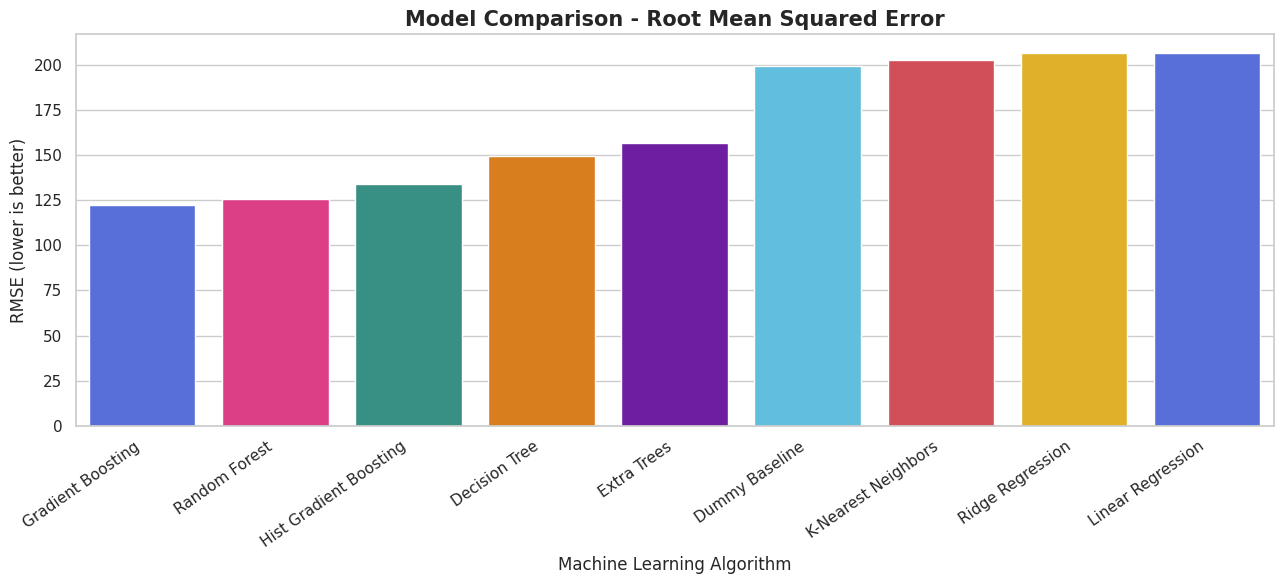

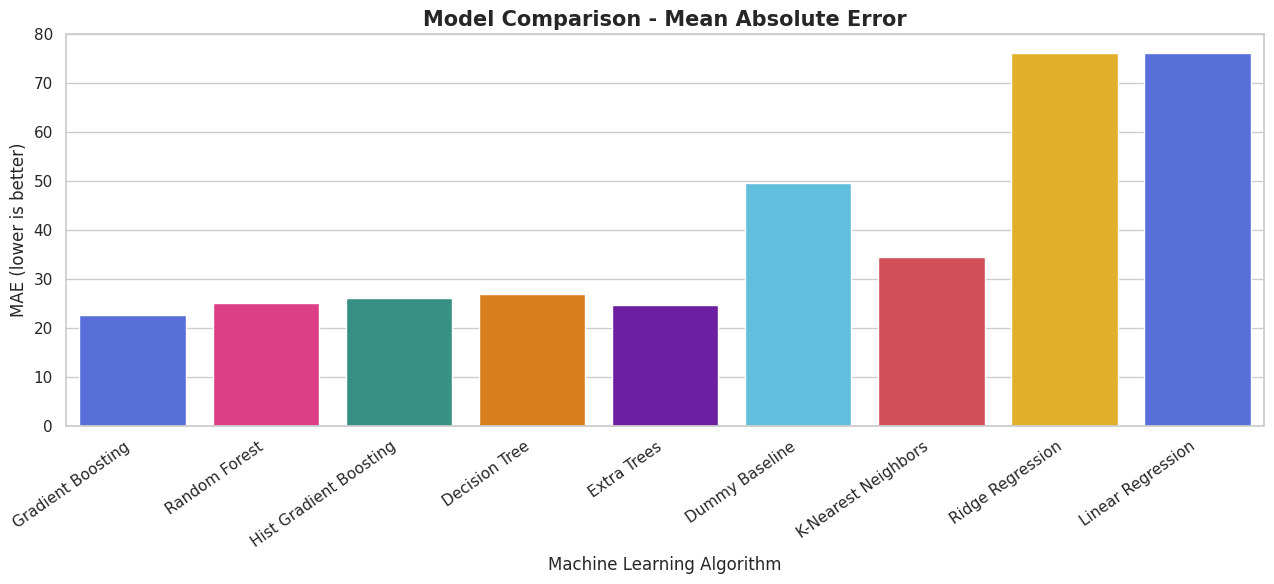

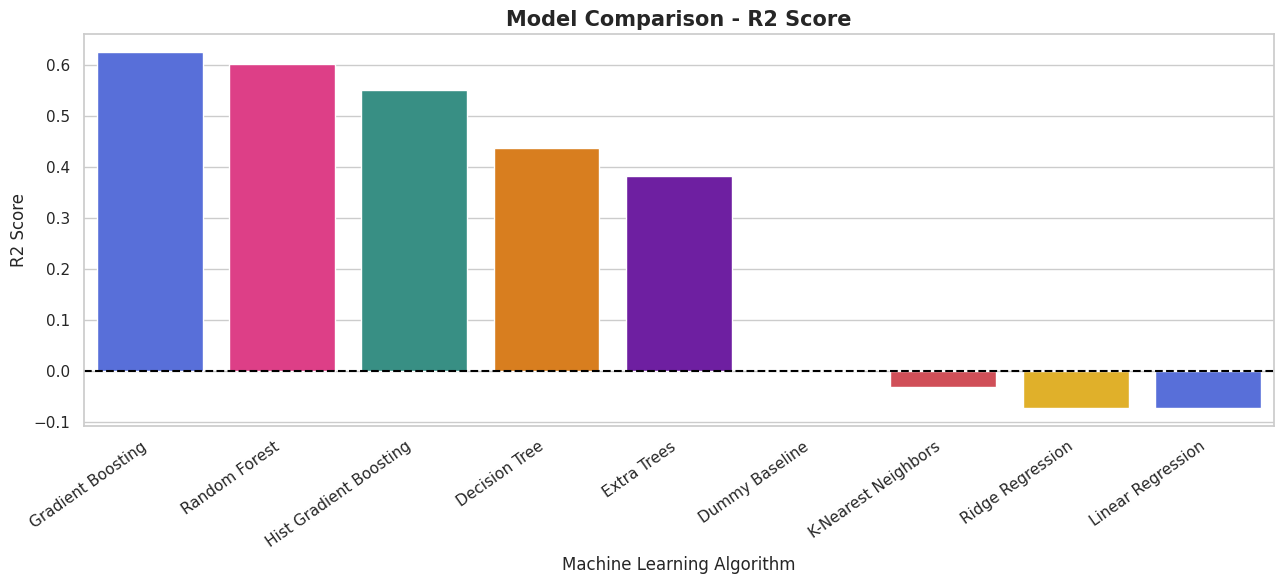

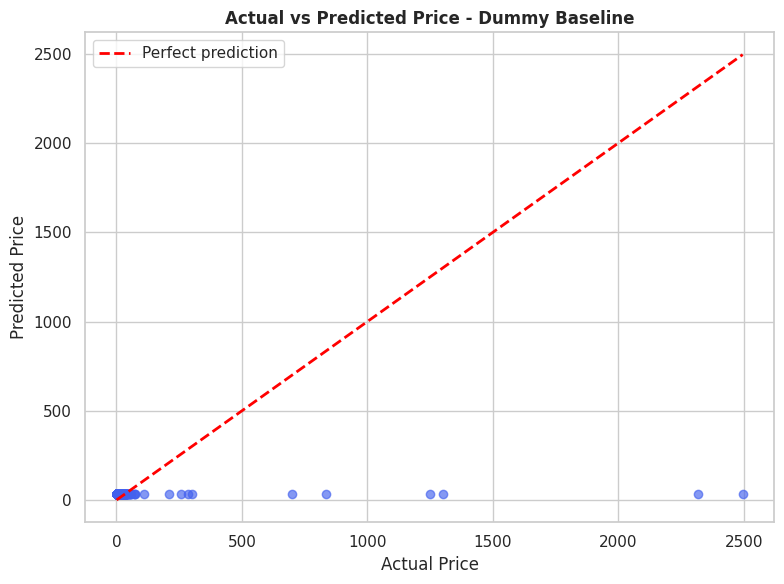

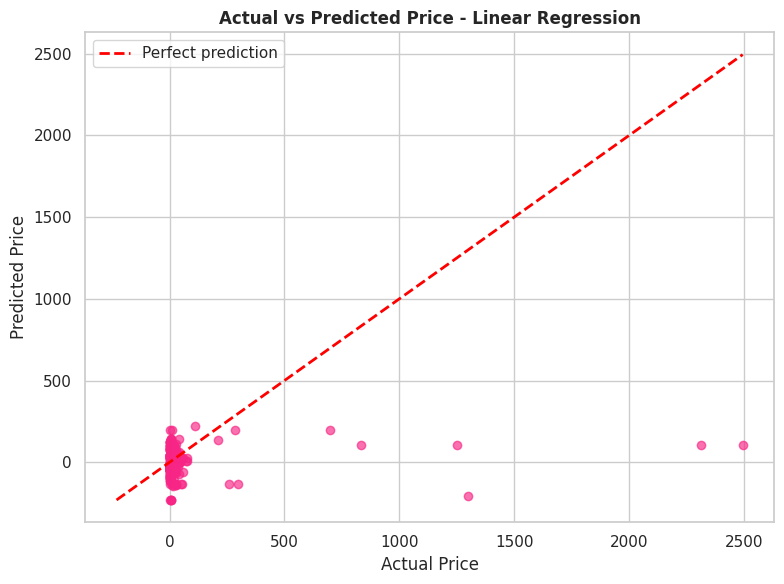

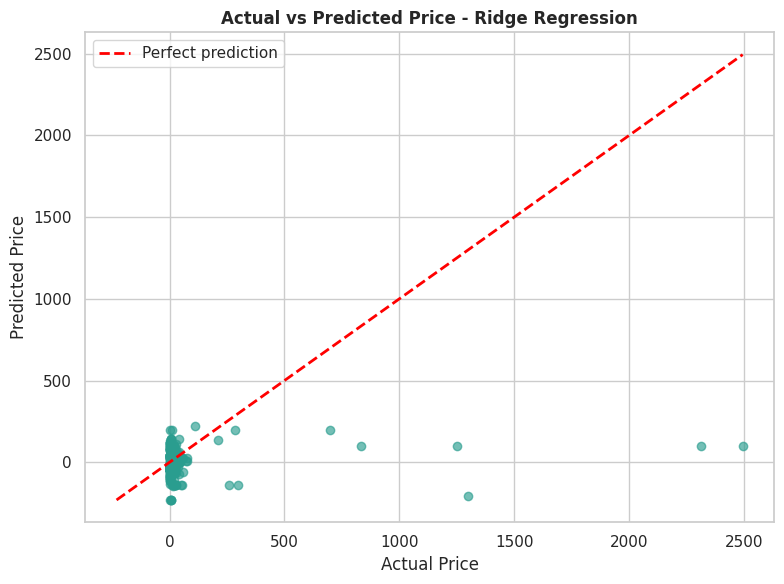

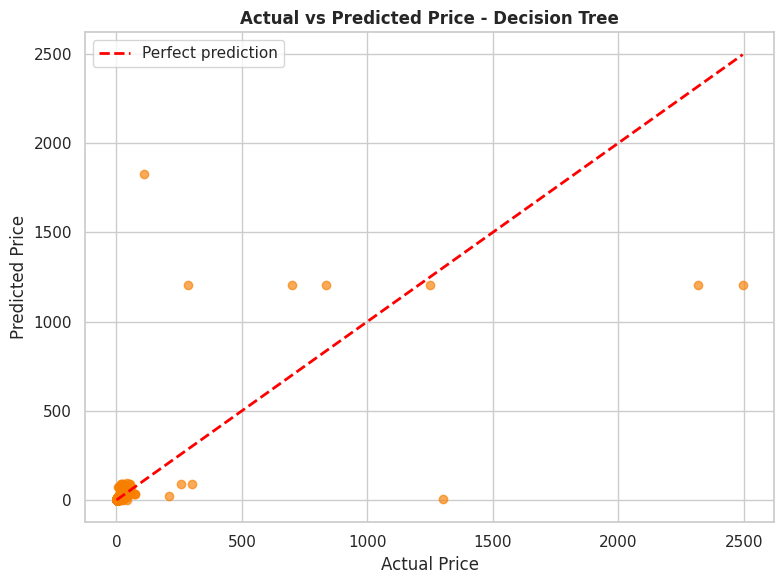

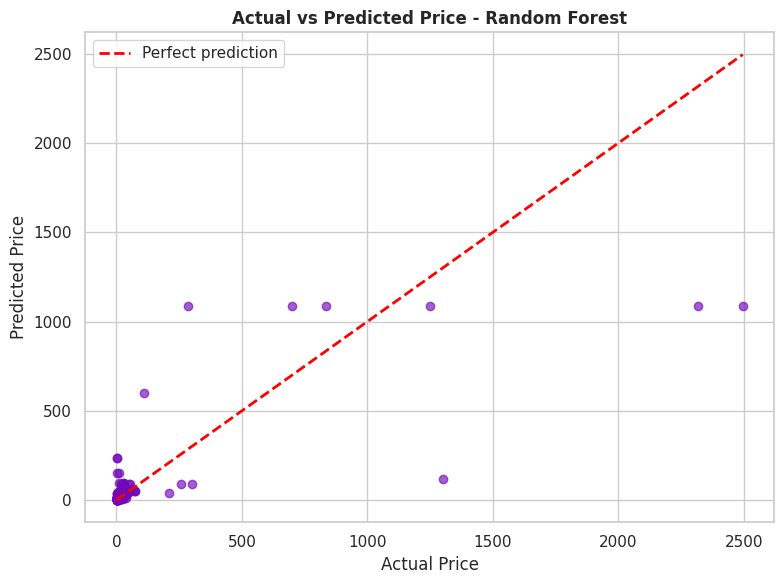

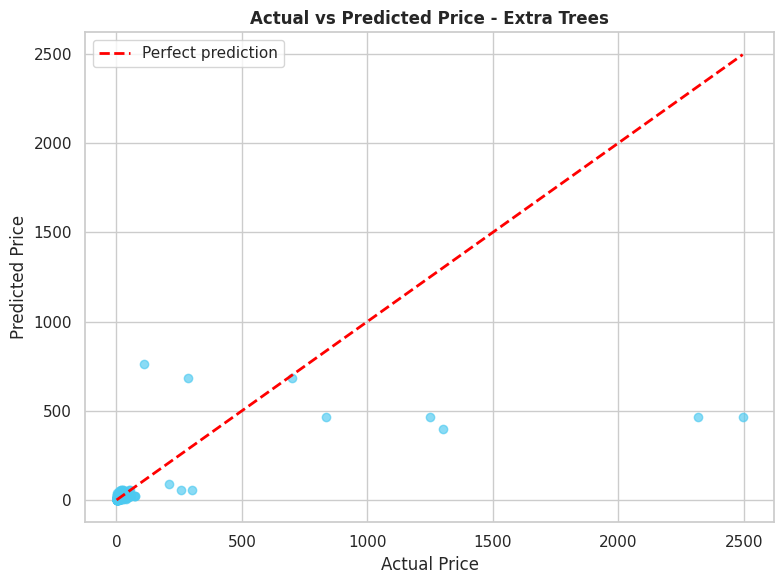

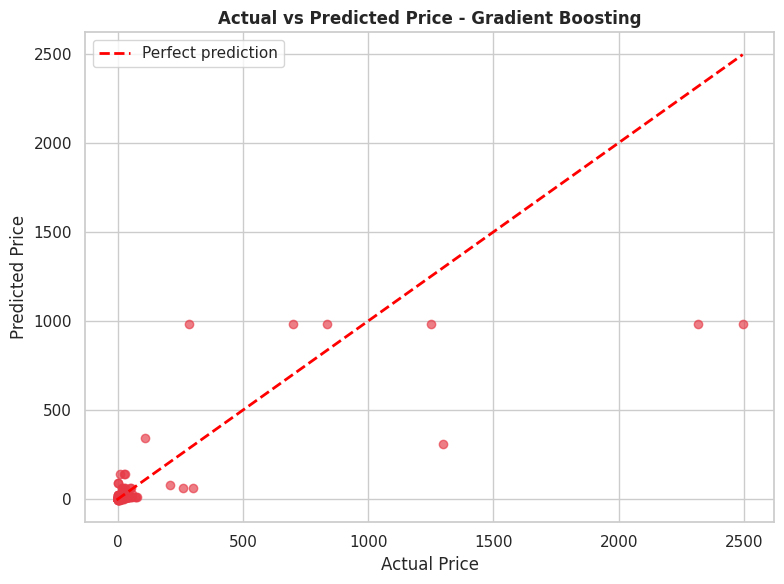

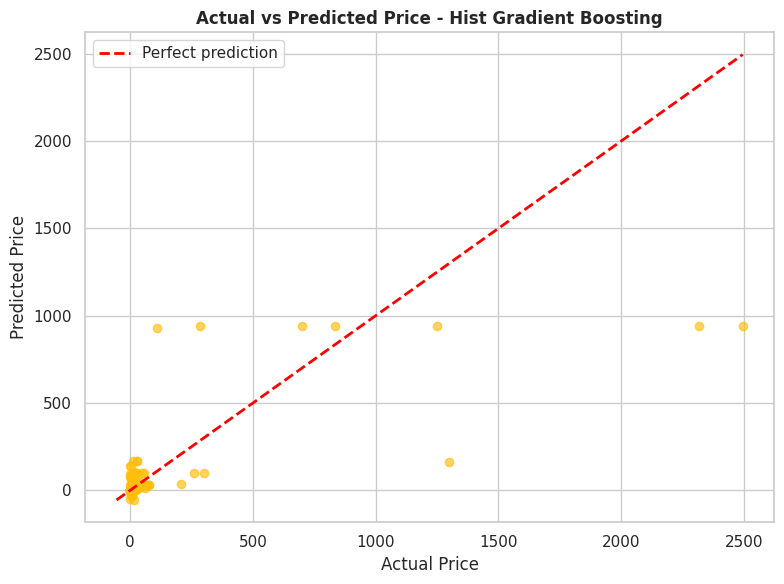

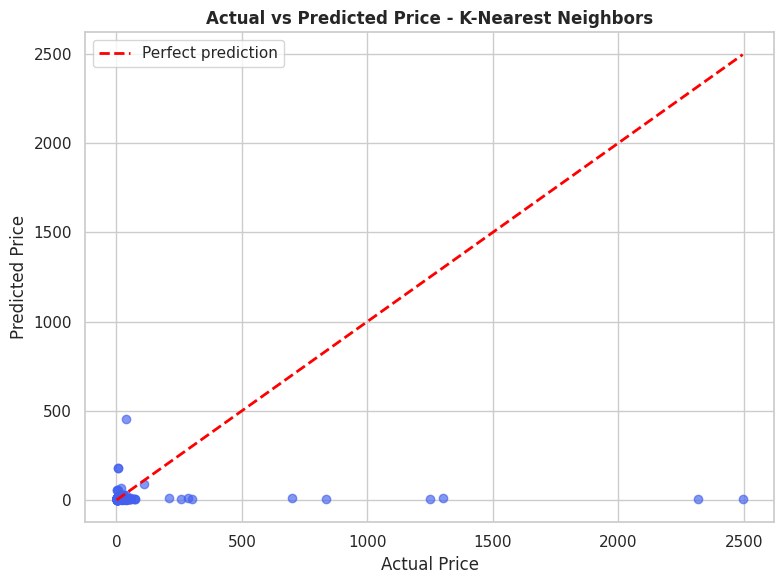

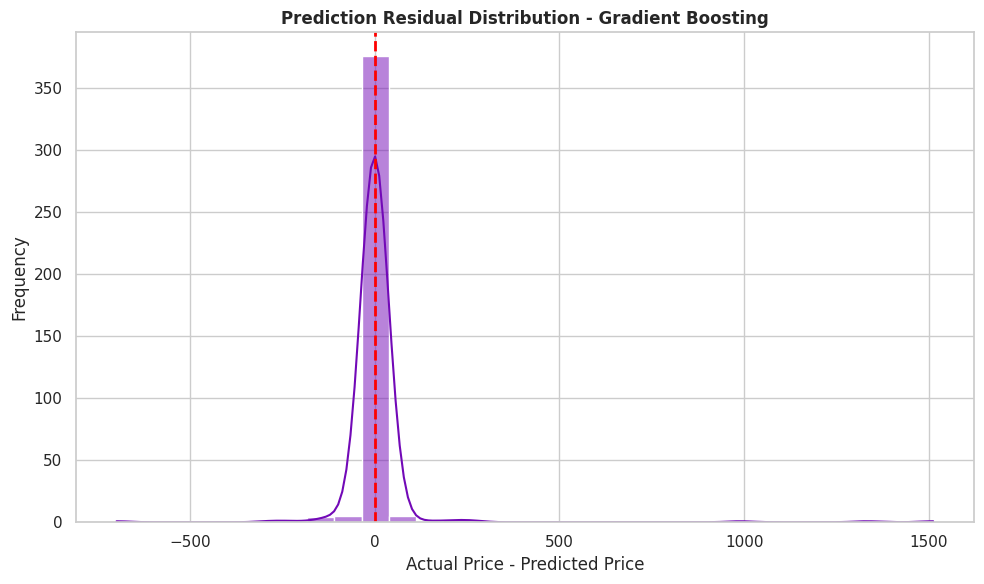

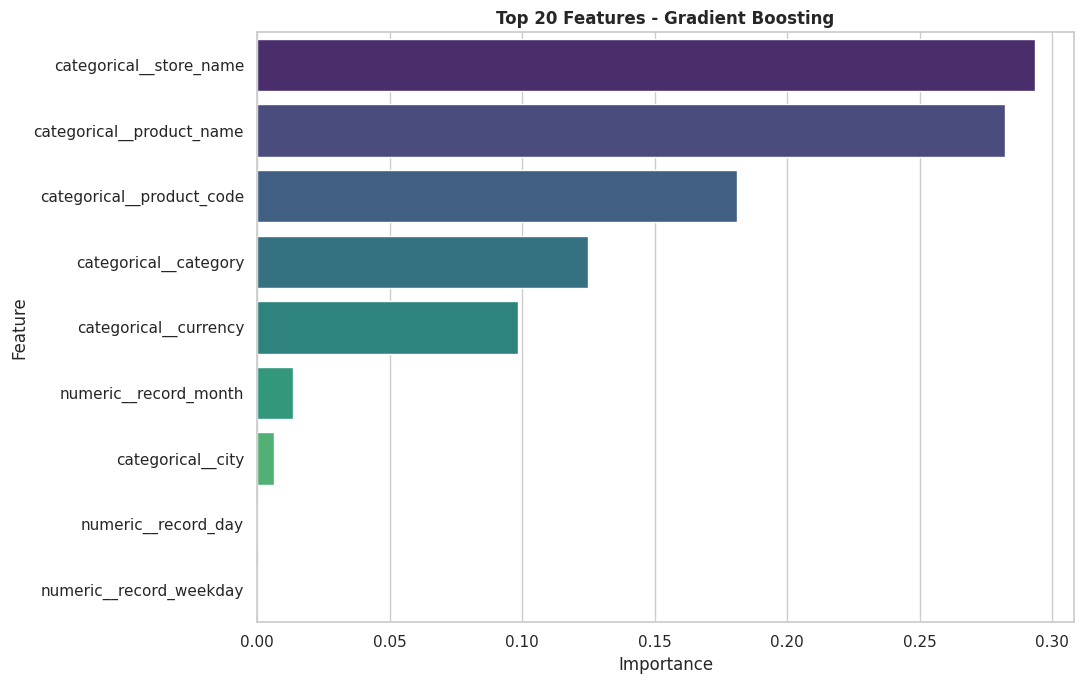


Top feature importance:
                  Feature  Importance
  categorical__store_name    0.293578
categorical__product_name    0.282321
categorical__product_code    0.181247
    categorical__category    0.124775
    categorical__currency    0.098389
    numeric__record_month    0.013376
        categorical__city    0.006278
      numeric__record_day    0.000028
  numeric__record_weekday    0.000008

Sample predictions:
                                   product_name    category currency  Actual_Price  Predicted_Price  Absolute_Error
                           MARL.KLASI.DORT 800G __MISSING__      CZK        299.00           61.963         237.037
                                    __MISSING__ __MISSING__      EUR          4.55            3.016           1.534
             LAVAZZA PERFETTO COFFEE 12 OZ PK 6 __MISSING__      USD         17.99           13.368           4.622
                BTE CAN KRONENBOURG 4.20D6X33CL __MISSING__      EUR          4.39            3.016           

In [17]:

# =====================================================================
# PRODUCT PRICE PREDICTION - COMPLETE MACHINE LEARNING REGRESSION
# Works even when price_is_discounted contains only one class.
# Target: price
# =====================================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# =====================================================================
# 1. SETTINGS AND VALIDATION
# =====================================================================

RANDOM_STATE = 42
TEST_SIZE = 0.20

sns.set_theme(style="whitegrid")

COLORS = [
    "#4361EE", "#F72585", "#2A9D8F", "#F77F00",
    "#7209B7", "#4CC9F0", "#E63946", "#FFBE0B"
]

if "df" not in globals():
    raise NameError("Please load your dataset into a DataFrame named df.")

if "price" not in df.columns:
    raise ValueError("The dataset must contain a 'price' column.")

data = df.copy()

print("=" * 80)
print("PRODUCT PRICE PREDICTION - MACHINE LEARNING")
print("=" * 80)

print("\nOriginal dataset shape:", data.shape)
print("\nDiscount status distribution:")
if "price_is_discounted" in data.columns:
    print(data["price_is_discounted"].value_counts(dropna=False))

# =====================================================================
# 2. CLEAN DATA
# =====================================================================

data["price"] = pd.to_numeric(data["price"], errors="coerce")
data = data.dropna(subset=["price"]).copy()
data = data[np.isfinite(data["price"])].copy()

if len(data) < 5:
    raise ValueError("At least 5 valid price records are required.")

# Remove duplicate complete records
data = data.drop_duplicates().copy()

# Remove ID columns to prevent identifier leakage
id_columns = [
    col for col in data.columns
    if col.lower() in ["price_record_id", "record_id", "id"]
    or col.lower().endswith("_id")
]

# Exclude the original target from features
drop_columns = id_columns + ["price"]

if "price_is_discounted" in data.columns:
    drop_columns.append("price_is_discounted")

# Convert date to useful numerical components
if "date_recorded" in data.columns:
    date_values = pd.to_datetime(data["date_recorded"], errors="coerce")
    data["record_year"] = date_values.dt.year
    data["record_month"] = date_values.dt.month
    data["record_day"] = date_values.dt.day
    data["record_weekday"] = date_values.dt.dayofweek
    drop_columns.append("date_recorded")

X = data.drop(
    columns=list(set(drop_columns).intersection(data.columns))
).copy()

y = data["price"].copy()

# Remove columns with no useful variation
constant_columns = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

if constant_columns:
    print("\nRemoving constant feature columns:", constant_columns)
    X = X.drop(columns=constant_columns)

if X.shape[1] == 0:
    raise ValueError(
        "No useful input features remain. More product attributes are needed."
    )

# Convert categorical columns to consistent strings
categorical_features = X.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Remove infinite values in numerical columns
for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")
    X[col] = X[col].replace([np.inf, -np.inf], np.nan)

for col in categorical_features:
    X[col] = X[col].astype("string").fillna("__MISSING__").astype(str)

print("\nCleaned dataset shape:", data.shape)
print("Number of input features:", X.shape[1])
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# =====================================================================
# 3. TRAIN-TEST SPLIT
# =====================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# =====================================================================
# 4. PREPROCESSING
# =====================================================================

transformers = []

if numeric_features:
    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

if categorical_features:
    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ])

    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

# =====================================================================
# 5. MACHINE LEARNING ALGORITHMS
# =====================================================================

models = {
    "Dummy Baseline": DummyRegressor(strategy="mean"),

    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=3,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=RANDOM_STATE
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.08,
        max_leaf_nodes=15,
        random_state=RANDOM_STATE
    ),

    "K-Nearest Neighbors": KNeighborsRegressor(
        n_neighbors=min(5, len(X_train))
    )
}

# =====================================================================
# 6. TRAIN AND EVALUATE
# =====================================================================

results = []
trained_models = {}
prediction_results = {}

for model_name, estimator in models.items():
    print("\n" + "=" * 70)
    print("Training:", model_name)
    print("=" * 70)

    try:
        pipeline = Pipeline(steps=[
            ("preprocessor", preprocessor),
            ("model", estimator)
        ])

        pipeline.fit(X_train, y_train)

        predictions = pipeline.predict(X_test)

        mae = mean_absolute_error(y_test, predictions)
        mse = mean_squared_error(y_test, predictions)
        rmse = np.sqrt(mse)

        # R2 may be undefined if the test target has only one unique value
        if y_test.nunique() > 1:
            r2 = r2_score(y_test, predictions)
        else:
            r2 = np.nan

        results.append({
            "Model": model_name,
            "MAE": mae,
            "MSE": mse,
            "RMSE": rmse,
            "R2 Score": r2
        })

        trained_models[model_name] = pipeline
        prediction_results[model_name] = predictions

        print(f"MAE:  {mae:.4f}")
        print(f"MSE:  {mse:.4f}")
        print(f"RMSE: {rmse:.4f}")
        print(f"R2:   {r2:.4f}" if np.isfinite(r2) else
              "R2: Undefined because test prices are constant")

    except Exception as error:
        print(f"Skipped {model_name}: {error}")

if not results:
    raise RuntimeError(
        "All models failed. Check whether the input features contain valid data."
    )

# =====================================================================
# 7. MODEL COMPARISON TABLE
# =====================================================================

results_df = pd.DataFrame(results).sort_values(
    "RMSE", ascending=True
).reset_index(drop=True)

print("\n" + "=" * 80)
print("MODEL COMPARISON - LOWER MAE/RMSE IS BETTER")
print("=" * 80)
print(results_df.round(4).to_string(index=False))

# =====================================================================
# 8. RMSE COMPARISON CHART
# =====================================================================

plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE",
    hue="Model",
    palette=COLORS,
    legend=False
)

plt.title("Model Comparison - Root Mean Squared Error", fontsize=15)
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("RMSE (lower is better)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# =====================================================================
# 9. MAE COMPARISON CHART
# =====================================================================

plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE",
    hue="Model",
    palette=COLORS,
    legend=False
)

plt.title("Model Comparison - Mean Absolute Error", fontsize=15)
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("MAE (lower is better)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# =====================================================================
# 10. R2 COMPARISON
# =====================================================================

r2_data = results_df.dropna(subset=["R2 Score"])

if not r2_data.empty:
    plt.figure(figsize=(13, 6))

    sns.barplot(
        data=r2_data,
        x="Model",
        y="R2 Score",
        hue="Model",
        palette=COLORS,
        legend=False
    )

    plt.axhline(0, linestyle="--", color="black")
    plt.title("Model Comparison - R2 Score", fontsize=15)
    plt.xlabel("Machine Learning Algorithm")
    plt.ylabel("R2 Score")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

# =====================================================================
# 11. ACTUAL VS PREDICTED PRICE FOR EACH MODEL
# =====================================================================

for index, (model_name, predictions) in enumerate(
    prediction_results.items()
):
    plt.figure(figsize=(8, 6))

    plt.scatter(
        y_test,
        predictions,
        alpha=0.65,
        color=COLORS[index % len(COLORS)]
    )

    low = min(float(y_test.min()), float(np.min(predictions)))
    high = max(float(y_test.max()), float(np.max(predictions)))

    plt.plot(
        [low, high],
        [low, high],
        linestyle="--",
        color="red",
        linewidth=2,
        label="Perfect prediction"
    )

    plt.title(f"Actual vs Predicted Price - {model_name}")
    plt.xlabel("Actual Price")
    plt.ylabel("Predicted Price")
    plt.legend()
    plt.tight_layout()
    plt.show()

# =====================================================================
# 12. RESIDUAL DISTRIBUTION FOR THE BEST MODEL
# =====================================================================

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = prediction_results[best_model_name]

residuals = y_test.to_numpy() - best_predictions

plt.figure(figsize=(10, 6))

sns.histplot(
    residuals,
    kde=True,
    color="#7209B7",
    bins=30
)

plt.axvline(0, color="red", linestyle="--", linewidth=2)
plt.title(f"Prediction Residual Distribution - {best_model_name}")
plt.xlabel("Actual Price - Predicted Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# =====================================================================
# 13. FEATURE IMPORTANCE
# =====================================================================

best_estimator = best_model.named_steps["model"]
fitted_preprocessor = best_model.named_steps["preprocessor"]

if hasattr(best_estimator, "feature_importances_"):
    try:
        feature_names = fitted_preprocessor.get_feature_names_out()

        importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Importance": best_estimator.feature_importances_
        }).sort_values(
            "Importance", ascending=False
        ).head(20)

        plt.figure(figsize=(11, 7))

        sns.barplot(
            data=importance_df,
            x="Importance",
            y="Feature",
            hue="Feature",
            palette="viridis",
            legend=False
        )

        plt.title(f"Top 20 Features - {best_model_name}")
        plt.tight_layout()
        plt.show()

        print("\nTop feature importance:")
        print(importance_df.to_string(index=False))

    except Exception as error:
        print("Feature importance could not be displayed:", error)

else:
    print(
        f"\n{best_model_name} does not provide built-in feature importance."
    )

# =====================================================================
# 14. SAMPLE PRICE PREDICTIONS
# =====================================================================

sample_count = min(20, len(X_test))

sample_df = X_test.iloc[:sample_count].copy()
sample_predictions = best_model.predict(sample_df)

prediction_df = sample_df.copy()
prediction_df["Actual_Price"] = y_test.iloc[:sample_count].to_numpy()
prediction_df["Predicted_Price"] = sample_predictions
prediction_df["Absolute_Error"] = np.abs(
    prediction_df["Actual_Price"] -
    prediction_df["Predicted_Price"]
)

display_columns = [
    col for col in [
        "product_name", "brand", "category", "currency",
        "Actual_Price", "Predicted_Price", "Absolute_Error"
    ]
    if col in prediction_df.columns
]

print("\nSample predictions:")
print(
    prediction_df[display_columns].round(3).to_string(index=False)
)

# =====================================================================
# 15. FINAL SUMMARY
# =====================================================================

print("\n" + "=" * 80)
print("FINAL SUMMARY")
print("=" * 80)

print("Original dataset rows:", len(df))
print("Rows after cleaning:", len(data))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Input features:", X.shape[1])
print("Models trained:", len(trained_models))
print("Best model by test RMSE:", best_model_name)
print("Best model RMSE:", round(results_df.iloc[0]["RMSE"], 4))

print("\nRegression analysis completed successfully.")
print("ROC curves are not applicable because this is price regression.")


## Thank you..pls upvote!!!!